## **Detecção de Tráfego Malicioso Desconhecido em Redes com OCC**

Importando as bibliotecas necessárias:

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score)
import matplotlib.pyplot as plt

Configurando caminhos locais para acesso ao dataset

In [ ]:
from pathlib import Path

def _achar_raiz():
    for base in [Path.cwd(), *Path.cwd().parents]:
        if ((base / "dataset").exists()
                or (base / "attack-detectionv2.ipynb").exists()):
            return base
    return Path.cwd()

ROOT = _achar_raiz()

# No Colab com Drive: se o CSV local nao existir, monta o Drive e usa ele.
try:
    import google.colab  # noqa
    _NO_COLAB = True
except ImportError:
    _NO_COLAB = False

if not (ROOT / "dataset" / "NF-UNSW-NB15-v2.csv").exists() and _NO_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    _pasta = Path('/content/drive/MyDrive/AM2')
    if (_pasta / "dataset" / "NF-UNSW-NB15-v2.csv").exists():
        ROOT = _pasta

DATASET_CSV = ROOT / "dataset" / "NF-UNSW-NB15-v2.csv"
CLEAN_PARQUET = ROOT / "nf_unsw_v2_clean.parquet"
SPLIT_PARQUET = ROOT / "nf_unsw_v2_split_A.parquet"
SPLITB_PARQUET = ROOT / "nf_unsw_v2_split_B.parquet"
SCORES_NPZ   = ROOT / "scores_supervisionado.npz"
IMAGES_DIR   = ROOT / "imagens"
IMAGES_DIR.mkdir(exist_ok=True)
print(f"ROOT={ROOT}")
print(f"CSV existe: {DATASET_CSV.exists()} -> {DATASET_CSV}")


ROOT=/home/gubuntu/Downloads/trabalho_1_AM2
CSV existe: True -> /home/gubuntu/Downloads/trabalho_1_AM2/dataset/NF-UNSW-NB15-v2.csv


Importando dataset:

In [ ]:
df = pd.read_csv(DATASET_CSV)

print(df.shape)
print(df.columns.tolist())
print(df['Attack'].value_counts())
df.info(memory_usage="deep")

(2390275, 45)
['IPV4_SRC_ADDR', 'L4_SRC_PORT', 'IPV4_DST_ADDR', 'L4_DST_PORT', 'PROTOCOL', 'L7_PROTO', 'IN_BYTES', 'IN_PKTS', 'OUT_BYTES', 'OUT_PKTS', 'TCP_FLAGS', 'CLIENT_TCP_FLAGS', 'SERVER_TCP_FLAGS', 'FLOW_DURATION_MILLISECONDS', 'DURATION_IN', 'DURATION_OUT', 'MIN_TTL', 'MAX_TTL', 'LONGEST_FLOW_PKT', 'SHORTEST_FLOW_PKT', 'MIN_IP_PKT_LEN', 'MAX_IP_PKT_LEN', 'SRC_TO_DST_SECOND_BYTES', 'DST_TO_SRC_SECOND_BYTES', 'RETRANSMITTED_IN_BYTES', 'RETRANSMITTED_IN_PKTS', 'RETRANSMITTED_OUT_BYTES', 'RETRANSMITTED_OUT_PKTS', 'SRC_TO_DST_AVG_THROUGHPUT', 'DST_TO_SRC_AVG_THROUGHPUT', 'NUM_PKTS_UP_TO_128_BYTES', 'NUM_PKTS_128_TO_256_BYTES', 'NUM_PKTS_256_TO_512_BYTES', 'NUM_PKTS_512_TO_1024_BYTES', 'NUM_PKTS_1024_TO_1514_BYTES', 'TCP_WIN_MAX_IN', 'TCP_WIN_MAX_OUT', 'ICMP_TYPE', 'ICMP_IPV4_TYPE', 'DNS_QUERY_ID', 'DNS_QUERY_TYPE', 'DNS_TTL_ANSWER', 'FTP_COMMAND_RET_CODE', 'Label', 'Attack']
Attack
Benign            2295222
Exploits            31551
Fuzzers             22310
Generic             16560

### **Pré-processamento**

Nesta etapa foram aplicadas apenas operações que **não dependem de estatísticas aprendidas dos dados**, e que por isso podem ser feitas antes da divisão entre treino e teste sem causar vazamento de informação.

Foram feitos:

- **Remoção de atributos de identificação:** manter esses atributos faria o modelo memorizar *quem* se comunica com *quem* em vez de aprender o *comportamento* do tráfego, o que comprometeria a generalização para ataques desconhecidos.

- **Verificações de integridade:**
  - a consistência entre `Label` (binário) e `Attack` (tipo): todo fluxo com `Label = 0` é `Benign` e todo fluxo com `Label = 1` pertence a uma das nove categorias de ataque;
  - a presença de valores nulos e infinitos: nenhum encontrado;
  - a existência de colunas constantes, que não carregam informação: nenhuma encontrada.

- **Otimização de memória:** uso de memória caiu de aproximadamente 887,3 MB para 280,4 MB, sem perda de informação.

- **Diagnóstico de duplicatas:** após a remoção dos identificadores, constatou-se que **1.662.276 dos 2.390.275 fluxos (~70%) são idênticos em todos os atributos a algum outro fluxo**. Além disso, 3.811 fluxos têm atributos idênticos, mas rótulos diferentes. Essas duplicatas foram apenas medidas nesta célula e tratadas na etapa seguinte.

In [ ]:
# Remover colunas de identificação
drop_cols = ['IPV4_SRC_ADDR', 'IPV4_DST_ADDR', 'L4_SRC_PORT', 'DNS_QUERY_ID']
df = df.drop(columns=drop_cols)

feat_cols = [c for c in df.columns if c not in ['Label', 'Attack']]

# 2) Consistência entre Label e Attack
print(pd.crosstab(df['Label'], df['Attack']))

# Nulos e infinitos
nulos = df.isna().sum()
print("Nulos:\n", nulos[nulos > 0])
print("Infinitos:", np.isinf(df[feat_cols].select_dtypes('number')).sum().sum())

# Colunas constantes
nuniq = df[feat_cols].nunique()
print("Constantes:", nuniq[nuniq <= 1].index.tolist())

# Medir duplicatas
dup_feat = df.duplicated(subset=feat_cols).sum()
dup_feat_attack = df.duplicated(subset=feat_cols + ['Attack']).sum()
print(f"Duplicatas nos atributos: {dup_feat}")
print(f"Duplicatas atributos+Attack: {dup_feat_attack}")
# diferença = fluxos idênticos com rótulos diferentes (ambíguos)
print(f"Idênticos com rótulo diferente: {dup_feat - dup_feat_attack}")

# Reduzir memória
for c in df.select_dtypes('int64').columns:
    df[c] = pd.to_numeric(df[c], downcast='integer')
for c in df.select_dtypes('float64').columns:
    df[c] = df[c].astype('float32')
df['Attack'] = df['Attack'].astype('category')

df.info(memory_usage='deep')

Attack  Analysis  Backdoor   Benign   DoS  Exploits  Fuzzers  Generic  \
Label                                                                   
0              0         0  2295222     0         0        0        0   
1           2299      2169        0  5794     31551    22310    16560   

Attack  Reconnaissance  Shellcode  Worms  
Label                                     
0                    0          0      0  
1                12779       1427    164  
Nulos:
 Series([], dtype: int64)
Infinitos: 0
Constantes: []
Duplicatas nos atributos: 1662276
Duplicatas atributos+Attack: 1658465
Idênticos com rótulo diferente: 3811
<class 'pandas.DataFrame'>
RangeIndex: 2390275 entries, 0 to 2390274
Data columns (total 41 columns):
 #   Column                       Dtype   
---  ------                       -----   
 0   L4_DST_PORT                  int32   
 1   PROTOCOL                     int16   
 2   L7_PROTO                     float32 
 3   IN_BYTES                     int32   
 4   I

### Deduplicação de tráfego

O dataset NF-UNSW-NB15-v2 baseia-se em fluxos NetFlow agregados, o que frequentemente resulta em vetores de atributos idênticos oriundos de momentos diferentes da captura. Manter esses fluxos inflaria o peso de comportamentos repetitivos e facilitaria o vazamento de dados entre treino e teste (memorização em vez de generalização).

A remoção de duplicatas (atributos + rótulo de ataque iguais) e de vetores ambíguos (atributos iguais, mas com rótulos diferentes) eliminou uma parcela massiva do dataset original:

- **Benign**: 2295222 -> 690555 (removidos 1604667, 69.9%)
- **Exploits**: 31551 -> 22411 (removidos 9140, 29.0%)
- **Fuzzers**: 22310 -> 6792 (removidos 15518, 69.6%)
- **Generic**: 16560 -> 1696 (removidos 14864, 89.8%)
- **Reconnaissance**: 12779 -> 248 (removidos 12531, 98.1%)
- **DoS**: 5794 -> 3035 (removidos 2759, 47.6%)
- **Analysis**: 2299 -> 336 (removidos 1963, 85.4%)
- **Backdoor**: 2169 -> 195 (removidos 1974, 91.0%)
- **Shellcode**: 1427 -> 1427 (removidos 0, 0.0%)
- **Worms**: 164 -> 45 (removidos 119, 72.6%)


**Análise de vetores idênticos com rótulos mistos:**
Não restou nenhum grupo idêntico com múltiplos rótulos após a deduplicação. Os grupos ambíguos foram totalmente removidos.

A redução drástica nas classes menores (como Reconnaissance, que perdeu 98,1%, ou Analysis e Backdoor) evidencia que o tráfego dessas categorias era altamente repetitivo no simulador.


In [ ]:
# Deduplicar por atributos + Attack
df_u = df.drop_duplicates(subset=feat_cols + ['Attack']).copy()

# Remover vetores de atributos idênticos com mais de um rótulo
h = pd.util.hash_pandas_object(df_u[feat_cols], index=False)
n_rot = df_u['Attack'].astype(str).groupby(h).transform('nunique')
df_clean = df_u[n_rot == 1].reset_index(drop=True)

# Verificação: cada vetor de atributos agora é único
assert not df_clean.duplicated(subset=feat_cols).any()

print(df_clean.shape)
print(df_clean['Attack'].value_counts())
print(f"Proporção de ataques: {df_clean['Label'].mean():.2%}")

# Salvar para não refazer (leitura bem mais rápida que o CSV)
df_clean.to_parquet(CLEAN_PARQUET, index=False)

(726740, 41)
Attack
Benign            690555
Exploits           22411
Fuzzers             6792
DoS                 3035
Generic             1696
Shellcode           1427
Analysis             336
Reconnaissance       248
Backdoor             195
Worms                 45
Name: count, dtype: int64
Proporção de ataques: 4.98%


In [ ]:
import pandas as pd
# Verificar deduplicação por classe e grupos mistos
print('=== Deduplicação por Classe ===')
c_raw = df['Attack'].astype(str).value_counts()
c_clean = df_clean['Attack'].astype(str).value_counts()
for k in c_raw.index:
    r = c_raw[k]
    c = c_clean.get(k, 0)
    rem = r - c
    pct = (rem / r) * 100 if r > 0 else 0
    print(f'{k}: {r} -> {c} (removidos {rem}, {pct:.1f}%)')

print('\n=== Análise de Vetores Idênticos com Rótulos Mistos ===')
# Encontrar grupos idênticos que têm mais de 1 rótulo único
feat_cols = [col for col in df.columns if col not in ['Label', 'Attack']]
grupos = df.groupby(feat_cols)['Attack'].nunique()
mistos = grupos[grupos > 1]
print(f'Nº de grupos idênticos com >1 rótulo único: {len(mistos)}')

# Quantos desses misturam Benign com algum ataque?
df_mistos = df.set_index(feat_cols).loc[mistos.index]
def tem_benign(g):
    return 'Benign' in g.values
mistos_com_benign = df_mistos.groupby(feat_cols)['Attack'].apply(tem_benign)
print(f'Nº de grupos mistos que incluem Benign: {sum(mistos_com_benign)}')


=== Deduplicação por Classe ===
Benign: 690555 -> 690555 (removidos 0, 0.0%)
Exploits: 22411 -> 22411 (removidos 0, 0.0%)
Fuzzers: 6792 -> 6792 (removidos 0, 0.0%)
DoS: 3035 -> 3035 (removidos 0, 0.0%)
Generic: 1696 -> 1696 (removidos 0, 0.0%)
Shellcode: 1427 -> 1427 (removidos 0, 0.0%)
Analysis: 336 -> 336 (removidos 0, 0.0%)
Reconnaissance: 248 -> 248 (removidos 0, 0.0%)
Backdoor: 195 -> 195 (removidos 0, 0.0%)
Worms: 45 -> 45 (removidos 0, 0.0%)

=== Análise de Vetores Idênticos com Rótulos Mistos ===
Nº de grupos idênticos com >1 rótulo único: 0
Nº de grupos mistos que incluem Benign: 0


Para simular a detecção de tráfego malicioso desconhecido, os tipos de ataque foram divididos em dois grupos:

- **Ataques conhecidos:** Exploits, Fuzzers, Generic e DoS. Estão presentes no treino e representam o que o sistema já viu.
- **Ataques desconhecidos:** Reconnaissance, Shellcode, Backdoor, Analysis e Worms. Aparecem **somente no teste**, simulando ameaças inéditas.

O tráfego benigno e os ataques conhecidos foram divididos de forma estratificada por tipo, na proporção 60% (treino), 20% (validação) e 20% (teste). Os ataques desconhecidos foram alocados integralmente ao teste. A validação não contém ataques desconhecidos, para que o ajuste de limiares e de regras de combinação de modelos não use informação sobre o que deveria ser inédito.

| Conjunto | Benigno | Ataques conhecidos | Ataques desconhecidos |
|---|---|---|---|
| Treino | 414.333 | 20.360 | 0 |
| Validação | 138.111 | 6.787 | 0 |
| Teste | 138.111 | 6.787 | 2.251 |

Como a deduplicação foi feita antes da divisão, nenhum vetor de atributos aparece em mais de um conjunto, o que evita vazamento por cópias idênticas. O conjunto de teste mantém a prevalência natural das classes (sem balanceamento), e eventuais técnicas de reamostragem foram aplicadas apenas ao treino. Transformações que dependem de estatísticas dos dados, como a padronização, foram ajustadas somente no treino.

**Limitação:** as classes desconhecidas têm poucos exemplos no teste (por exemplo, 45 fluxos de Worms), então métricas por classe devem ser interpretadas com cautela, sendo mais confiável analisar também o desempenho agregado sobre os desconhecidos.

In [ ]:
SEED = 42

def fazer_split(df, conhecidos, desconhecidos, seed=SEED):
    """
        Retorna df com coluna 'split' (train/val/test) e 'grupo' (benigno/conhecido/desconhecido).
    """
    df = df.copy()
    att = df['Attack'].astype(str)

    pool = df[att.isin(['Benign'] + conhecidos)]
    y = pool['Attack'].astype(str)

    tv_idx, te_idx = train_test_split(pool.index, test_size=0.20, stratify=y, random_state=seed)
    tr_idx, va_idx = train_test_split(tv_idx, test_size=0.25,
                                      stratify=y.loc[tv_idx], random_state=seed)  # 60/20/20

    df['split'] = 'descartado'
    df.loc[tr_idx, 'split'] = 'train'
    df.loc[va_idx, 'split'] = 'val'
    df.loc[te_idx, 'split'] = 'test'
    df.loc[att.isin(desconhecidos), 'split'] = 'test'   # desconhecidos só no teste

    df['grupo'] = np.where(att == 'Benign', 'benigno',
                   np.where(att.isin(conhecidos), 'conhecido', 'desconhecido'))
    return df

conhecidos    = ['Exploits', 'Fuzzers', 'Generic', 'DoS']
desconhecidos = ['Reconnaissance', 'Shellcode', 'Backdoor', 'Analysis', 'Worms']

df_split = fazer_split(df_clean, conhecidos, desconhecidos)

print(pd.crosstab(df_split['Attack'].astype(str), df_split['split']))
df_split.to_parquet(SPLIT_PARQUET, index=False)

split             test   train     val
Attack                                
Analysis           336       0       0
Backdoor           195       0       0
Benign          138111  414333  138111
DoS                607    1821     607
Exploits          4482   13446    4483
Fuzzers           1359    4075    1358
Generic            339    1018     339
Reconnaissance     248       0       0
Shellcode         1427       0       0
Worms               45       0       0


### **Aprendizado Supervisionado**

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.pipeline import make_pipeline
from xgboost import XGBClassifier

Carregamos os dados salvos anteriormente e os separamos nas partições definidas de treino (`train`), validação (`val`) e teste (`test`). Selecionamos apenas os atributos de características explicativas (features) em `feat_cols` e os rótulos de classe (`Label`).

In [ ]:
df = pd.read_parquet(SPLIT_PARQUET)
feat_cols = [c for c in df.columns if c not in ['Label', 'Attack', 'split', 'grupo']]

tr = df[df['split'] == 'train']
va = df[df['split'] == 'val']
te = df[df['split'] == 'test']

X_tr, y_tr = tr[feat_cols].astype('float32'), tr['Label']
X_va, y_va = va[feat_cols].astype('float32'), va['Label']
X_te, y_te = te[feat_cols].astype('float32'), te['Label']

print(X_tr.shape, X_va.shape, X_te.shape)
print("Ataques no treino:", y_tr.mean())

(434693, 39) (144898, 39) (147149, 39)
Ataques no treino: 0.04683765324033283


Aqui definimos funções auxiliares fundamentais para automatizar o processo:
- `treinar_supervisionado` e `scores_supervisionado`: ajustam os modelos e calculam as probabilidades de anomalia.
- `limiar_por_fpr`: define o ponto de corte com base em uma taxa de falsos positivos (FPR) desejada (ex: 1%).
- `bootstrap_recall`: utiliza reamostragem estatística para estimar intervalos de confiança para a métrica de revocação (Recall).
- `avaliar_long`: computa as métricas de desempenho em formato longo por grupos de ataques conhecidos e desconhecidos.

In [ ]:
def treinar_supervisionado(modelo_cls, X_tr, y_tr, cols, **kwargs):
    m = modelo_cls(**kwargs)
    m.fit(X_tr[cols], y_tr)
    return m

def scores_supervisionado(modelo, X, cols):
    return modelo.predict_proba(X[cols])[:, 1]

def limiar_por_fpr(s_val, y_val, fpr_alvo):
    return np.quantile(s_val[y_val == 0], 1 - fpr_alvo)

def bootstrap_recall(pred, mask, n_boot=1000, seed=0):
    rng = np.random.default_rng(seed)
    idx = np.where(mask)[0]
    if len(idx) == 0:
        return np.nan, np.nan
    amostras = [pred[rng.choice(idx, size=len(idx), replace=True)].mean()
                for _ in range(n_boot)]
    return np.percentile(amostras, [2.5, 97.5])

def avaliar_long(nome_modelo, s_te, y_te, att_te, grupo_te, thr, extra=None, n_boot=1000):
    pred = (s_te > thr).astype(int)
    linhas = []
    base = dict(modelo=nome_modelo, **(extra or {}))

    linhas.append({**base, 'metrica': 'FPR_benigno', 'categoria': 'Benign',
                    'valor': pred[att_te == 'Benign'].mean()})
    linhas.append({**base, 'metrica': 'roc_auc_global',
                    'categoria': 'todos', 'valor': roc_auc_score(y_te, s_te)})
    linhas.append({**base, 'metrica': 'pr_auc_global',
                    'categoria': 'todos', 'valor': average_precision_score(y_te, s_te)})
    linhas.append({**base, 'metrica': 'precision_global',
                    'categoria': 'todos', 'valor': precision_score(y_te, pred, zero_division=0)})

    for g in ['conhecido', 'desconhecido']:
        mk = (grupo_te == 'benigno') | (grupo_te == g)
        linhas.append({**base, 'metrica': 'roc_auc', 'categoria': g,
                        'valor': roc_auc_score(y_te[mk], s_te[mk])})
        linhas.append({**base, 'metrica': 'recall', 'categoria': g,
                        'valor': pred[grupo_te == g].mean()})
        linhas.append({**base, 'metrica': 'precision', 'categoria': g,
                        'valor': precision_score(y_te[mk], pred[mk], zero_division=0)})

    for a in sorted(set(att_te) - {'Benign'}):
        mask = (att_te == a)
        n = mask.sum()
        valor = pred[mask].mean()
        lo, hi = bootstrap_recall(pred, mask, n_boot=n_boot)
        linhas.append({**base, 'metrica': 'recall', 'categoria': a,
                        'valor': valor, 'n': n, 'ic_lo': lo, 'ic_hi': hi})
    return linhas

Executamos o pipeline completo para os três algoritmos utilizando hiperparâmetros que tratam o desbalanceamento das classes (como `class_weight` e `scale_pos_weight`). Os limiares de decisão são calibrados no conjunto de validação antes de extrairmos as métricas finais de teste.

In [ ]:
# Peso de classe para o XGBoost
neg = (y_tr == 0).sum()
pos = (y_tr == 1).sum()

# Metadados do conjunto de teste usados em avaliar_long
att_te = te['Attack'].astype(str).values
grupo_te = te['grupo'].values

# Seleciona as features exceto as excluídas (usado na ablação)
def sem(excluir):
    return [c for c in feat_cols if c not in excluir]

In [ ]:
from numpy import log1p as _log1p

resultados = []
cols_base = feat_cols

# LogReg requer pré-processamento: log1p suaviza caudas longas,
# StandardScaler coloca as features na mesma escala antes do solver.
_pipe_lr = make_pipeline(
    FunctionTransformer(_log1p, validate=False),
    StandardScaler(),
    LogisticRegression(max_iter=1000, class_weight='balanced', C=0.1,
                       solver='lbfgs', n_jobs=-1),
)

for nome, modelo in [
    ('LogReg',       _pipe_lr),
    ('RandomForest', RandomForestClassifier(
                         n_estimators=200, n_jobs=-1,
                         class_weight='balanced_subsample', random_state=42)),
    ('XGBoost',      XGBClassifier(
                         n_estimators=300, max_depth=8, learning_rate=0.1,
                         scale_pos_weight=neg/pos, tree_method='hist',
                         random_state=42)),
]:
    modelo.fit(X_tr[cols_base], y_tr)
    s_va = modelo.predict_proba(X_va[cols_base])[:, 1]
    s_te = modelo.predict_proba(X_te[cols_base])[:, 1]
    thr  = limiar_por_fpr(s_va, y_va.values, fpr_alvo=0.01)
    resultados += avaliar_long(nome, s_te, y_te.values, att_te, grupo_te, thr,
                               extra={'features': 'completo', 'fpr_alvo': 0.01})

df_resultados = pd.DataFrame(resultados)


/home/gubuntu/Downloads/trabalho_1_AM2/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


Aqui formatamos os resultados obtidos, apresentando o Recall para cada categoria de ataque individualmente com seus respectivos intervalos de confiança em formato tabular.

In [ ]:
def formatar_ic(row):
    if pd.isna(row.get('ic_lo')):
        return f"{row['valor']:.3f}"
    return f"{row['valor']:.3f} [{row['ic_lo']:.3f}, {row['ic_hi']:.3f}]"

df_resultados['valor_fmt'] = df_resultados.apply(formatar_ic, axis=1)
df_resultados['metrica_completa'] = df_resultados['metrica'] + ' | ' + df_resultados['categoria']

tabela_geral = (df_resultados
    .query("features == 'completo'")
    .pivot_table(index='metrica_completa', columns='modelo', values='valor_fmt', aggfunc='first'))

ordem = [
    'FPR_benigno | Benign',
    'roc_auc_global | todos',
    'pr_auc_global | todos',
    'precision_global | todos',
    'roc_auc | conhecido',
    'roc_auc | desconhecido',
    'precision | conhecido',
    'precision | desconhecido',
    'recall | conhecido',
    'recall | desconhecido',
    'recall | Analysis', 'recall | Backdoor', 'recall | DoS', 'recall | Exploits',
    'recall | Fuzzers', 'recall | Generic', 'recall | Reconnaissance',
    'recall | Shellcode', 'recall | Worms',
]

tabela_geral = tabela_geral.reindex(ordem)
pd.set_option('display.max_rows', None)
display(tabela_geral)

modelo,LogReg,RandomForest,XGBoost
metrica_completa,,,
FPR_benigno | Benign,0.010,0.010,0.010
roc_auc_global | todos,0.992,0.997,0.998
pr_auc_global | todos,0.810,0.953,0.965
precision_global | todos,0.817,0.871,0.871
roc_auc | conhecido,0.993,0.998,0.999
roc_auc | desconhecido,0.990,0.994,0.998
precision | conhecido,0.782,0.836,0.835
precision | desconhecido,0.470,0.621,0.624
recall | conhecido,0.736,0.994,0.997


Gera um gráfico de barras ilustrando graficamente a revocação de cada ataque junto com suas margens de erro calculadas via bootstrap.

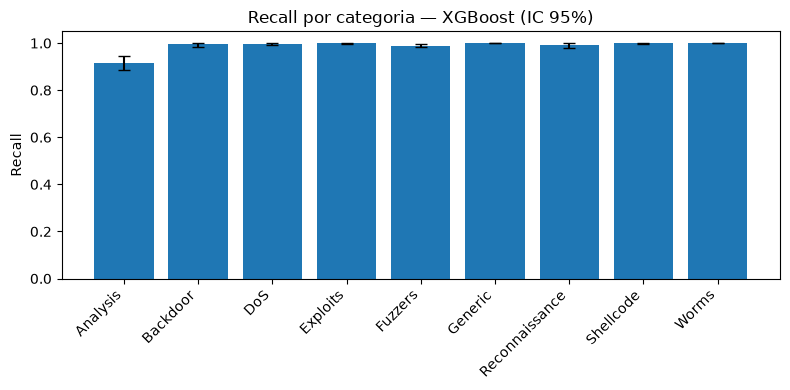

Gráfico salvo em: /home/gubuntu/Downloads/trabalho_1_AM2/imagens/recall_XGBoost_completo.png


In [ ]:
def plot_recall_com_ic(df, modelo, features='completo'):
    d = df.query("metrica == 'recall' and modelo == @modelo and features == @features "
                 "and categoria not in ['conhecido', 'desconhecido']").sort_values('categoria')

    yerr = [d['valor'] - d['ic_lo'], d['ic_hi'] - d['valor']]

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.bar(d['categoria'], d['valor'], yerr=yerr, capsize=4)
    ax.set_ylabel('Recall')
    ax.set_ylim(0, 1.05)
    ax.set_title(f'Recall por categoria — {modelo} (IC 95%)')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()

    fname = IMAGES_DIR / f"recall_{modelo}_{features}.png".replace(" ", "_")
    fig.savefig(fname, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Gráfico salvo em: {fname}")

plot_recall_com_ic(df_resultados, 'XGBoost')


Avaliamos a importância de certos conjuntos de variáveis (como valores de TTL, parâmetros de janela TCP e portas) treinando novos modelos sob a exclusão incremental dessas características para entender o impacto direto na capacidade de generalização.

In [ ]:
from numpy import log1p as _log1p

resultados_ablacao = []

def _fazer_logreg():
    """Retorna um pipeline fresco de LogReg (deve ser recriado a cada fit)."""
    return make_pipeline(
        FunctionTransformer(_log1p, validate=False),
        StandardScaler(),
        LogisticRegression(max_iter=1000, class_weight='balanced',
                           C=0.1, solver='lbfgs', n_jobs=-1),
    )

modelos_config = {
    'LogReg':       lambda: _fazer_logreg(),
    'RandomForest': lambda: RandomForestClassifier(
                         n_estimators=200, n_jobs=-1,
                         class_weight='balanced_subsample', random_state=42),
    'XGBoost':      lambda: XGBClassifier(
                         n_estimators=300, max_depth=8, learning_rate=0.1,
                         scale_pos_weight=neg/pos, tree_method='hist',
                         random_state=42),
}

conjuntos = {
    '-TTL': sem(['MIN_TTL', 'MAX_TTL']),
    '-TTL -janela TCP': sem(['MIN_TTL', 'MAX_TTL', 'TCP_WIN_MAX_IN', 'TCP_WIN_MAX_OUT']),
    '-TTL -janela -porta': sem(['MIN_TTL', 'MAX_TTL', 'TCP_WIN_MAX_IN',
                                'TCP_WIN_MAX_OUT', 'L4_DST_PORT']),
}

for nome_modelo, faz_modelo in modelos_config.items():
    for nome_conj, cols in conjuntos.items():
        m = faz_modelo()          # nova instância por iteração
        m.fit(X_tr[cols], y_tr)
        s_va = m.predict_proba(X_va[cols])[:, 1]
        s_te = m.predict_proba(X_te[cols])[:, 1]
        thr  = limiar_por_fpr(s_va, y_va.values, fpr_alvo=0.01)
        resultados_ablacao += avaliar_long(
            nome_modelo, s_te, y_te.values, att_te, grupo_te, thr,
            extra={'features': nome_conj, 'fpr_alvo': 0.01}
        )

df_ablacao = pd.DataFrame(resultados_ablacao)


/home/gubuntu/Downloads/trabalho_1_AM2/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/gubuntu/Downloads/trabalho_1_AM2/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/gubuntu/Downloads/trabalho_1_AM2/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


Filtramos e reordenamos a tabela de ablação para focar estritamente na capacidade de detecção (Recall) de ataques previamente não identificados (desconhecidos).

In [ ]:
df_ablacao['valor_fmt'] = df_ablacao.apply(formatar_ic, axis=1)
df_ablacao['metrica_completa'] = df_ablacao['metrica'] + ' | ' + df_ablacao['categoria']

# Geramos a tabela geral usando múltiplos índices (recursos de ablação e métricas) para cruzar com os modelos
tabela_geral_ablacao = (df_ablacao
    .pivot_table(index=['features', 'metrica_completa'], columns='modelo', values='valor_fmt', aggfunc='first'))

ordem_metricas = [
    'FPR_benigno | Benign',
    'roc_auc_global | todos',
    'pr_auc_global | todos',
    'precision_global | todos',
    'roc_auc | conhecido',
    'roc_auc | desconhecido',
    'precision | conhecido',
    'precision | desconhecido',
    'recall | conhecido',
    'recall | desconhecido',
    'recall | Analysis', 'recall | Backdoor', 'recall | DoS', 'recall | Exploits',
    'recall | Fuzzers', 'recall | Generic', 'recall | Reconnaissance',
    'recall | Shellcode', 'recall | Worms',
]

# Reordenamos o índice multinível de forma limpa
tabela_geral_ablacao = tabela_geral_ablacao.reindex(ordem_metricas, level='metrica_completa')
tabela_geral_ablacao = tabela_geral_ablacao.reindex(['-TTL', '-TTL -janela TCP', '-TTL -janela -porta'], level='features')

pd.set_option('display.max_rows', None)
display(tabela_geral_ablacao)

modelo                                                      LogReg  \
features            metrica_completa                                 
-TTL                FPR_benigno | Benign                     0.009   
                    roc_auc_global | todos                   0.985   
                    pr_auc_global | todos                    0.667   
                    precision_global | todos                 0.636   
                    roc_auc | conhecido                      0.986   
                    roc_auc | desconhecido                   0.981   
                    precision | conhecido                    0.589   
                    precision | desconhecido                 0.239   
                    recall | conhecido                       0.276   
                    recall | desconhecido                    0.183   
                    recall | Analysis         0.976 [0.961, 0.991]   
                    recall | Backdoor         0.097 [0.056, 0.138]   
                    recall | DoS              0.417 [0.379, 0.455]   
                    recall | Exploits         0.303 [0.290, 0.316]   
                    recall | Fuzzers          0.077 [0.063, 0.092]   
                    recall | Generic          0.469 [0.413, 0.522]   
                    recall | Reconnaissance   0.202 [0.153, 0.254]   
                    recall | Shellcode        0.001 [0.000, 0.004]   
                    recall | Worms            0.267 [0.133, 0.400]   
-TTL -janela TCP    FPR_benigno | Benign                     0.010   
                    roc_auc_global | todos                   0.979   
                    pr_auc_global | todos                    0.666   
                    precision_global | todos                 0.695   
                    roc_auc | conhecido                      0.984   
                    roc_auc | desconhecido                   0.962   
                    precision | conhecido                    0.650   
                    precision | desconhecido                 0.295   
                    recall | conhecido                       0.383   
                    recall | desconhecido                    0.260   
                    recall | Analysis         0.982 [0.967, 0.994]   
                    recall | Backdoor         0.154 [0.103, 0.205]   
                    recall | DoS              0.527 [0.486, 0.565]   
                    recall | Exploits         0.384 [0.371, 0.398]   
                    recall | Fuzzers          0.286 [0.261, 0.311]   
                    recall | Generic          0.501 [0.448, 0.555]   
                    recall | Reconnaissance   0.847 [0.802, 0.887]   
                    recall | Shellcode        0.000 [0.000, 0.000]   
                    recall | Worms            0.333 [0.200, 0.489]   
-TTL -janela -porta FPR_benigno | Benign                     0.010   
                    roc_auc_global | todos                   0.981   
                    pr_auc_global | todos                    0.632   
                    precision_global | todos                 0.629   
                    roc_auc | conhecido                      0.980   
                    roc_auc | desconhecido                   0.982   
                    precision | conhecido                    0.570   
                    precision | desconhecido                 0.269   
                    recall | conhecido                       0.266   
                    recall | desconhecido                    0.222   
                    recall | Analysis         0.946 [0.923, 0.970]   
                    recall | Backdoor         0.113 [0.072, 0.159]   
                    recall | DoS              0.356 [0.320, 0.397]   
                    recall | Exploits         0.283 [0.269, 0.296]   
                    recall | Fuzzers          0.156 [0.138, 0.176]   
                    recall | Generic          0.327 [0.274, 0.375]   
                    recall | Reconnaissance   0.145 [0.105, 0.190]   
          

#### **Conclusões (LEIA)**

### Conclusões do aprendizado supervisionado

1. **Os três modelos resolvem o split A com alto recall.** O XGBoost atinge 0,985 de recall em ataques desconhecidos a 1% de FPR.
2. **A ablação não é estritamente monotônica.** A remoção do L4_DST_PORT aumentou levemente o recall. Como o procedimento é incremental, os efeitos de cada coluna estão confundidos com as anteriores, impedindo afirmações robustas de causalidade sobre a importância estrutural do TTL, janela ou porta.
3. **Modelos em árvore são mais robustos na ablação do que modelos lineares.** A Regressão Logística foi significativamente impactada pela remoção de features na ablação, enquanto XGBoost e Random Forest se adaptaram melhor. Vale ressaltar que o pipeline da Regressão Logística é crucial: um retreino acidental sem `log1p` e `StandardScaler` produziu um recall de desconhecidos de apenas 0,001 a 1% de FPR, evidenciando a forte dependência do modelo linear pelo pré-processamento.


### **OCC: One-class Classification**

Na abordagem supervisionada, o modelo aprendeu a distinguir tráfego benigno de ataques conhecidos. Isso, porém, pressupõe que o modelo "viu" exemplos de ataque durante o treino. O OCC (One-Class Classification) parte de uma premissa diferente: o modelo é treinado exclusivamente sobre tráfego benigno e aprende a modelar o que é "normal". Qualquer fluxo que se desvia dessa normalidade é classificado como anômalo — sem precisar conhecer os tipos de ataque de antemão. Esse é o cenário real de um sistema de detecção de intrusão implantado em produção. Foram escolhidos dois modelos de naturezas complementares:

- **Isolation Forest (IF):** baseado em árvores de partição aleatória. A ideia é que pontos anômalos são "poucos e diferentes", portanto são isolados com poucos cortes, enquanto pontos normais, em regiões densas, exigem muitos cortes. O score de anomalia é função do comprimento médio do caminho até o isolamento. É escalável (custo aproximadamente linear), não depende de métrica de distância e permite usar todos os 414 mil fluxos benignos do treino.
- **One-Class SVM (OCSVM) com kernel RBF:** aprende uma fronteira em torno da região onde o tráfego benigno se concentra, mapeando os dados para um espaço de alta dimensão. Fluxos fora dessa fronteira recebem score de anomalia alto. Diferente do IF, ele captura a *forma* da região normal por meio de similaridade (distância), e não por cortes alinhados aos eixos. Seu custo de treino é aproximadamente quadrático no número de amostras, por isso ele é treinado em uma subamostra aleatória do tráfego benigno.

Os dois modelos "enxergam" a normalidade de formas distintas (partições vs. fronteira de densidade), o que torna a comparação mais informativa.

#### **Treinamento**

Todo o ajuste usa **exclusivamente** os fluxos benignos do conjunto de treino (`X_tr[y_tr == 0]`, 414.333 fluxos). Nenhum ataque, conhecido ou desconhecido, é visto durante o ajuste dos modelos. Etapas:

1. **Pré-processamento ajustado só no benigno do treino.** Atributos NetFlow (bytes, pacotes, duração, vazão) têm caudas muito pesadas, o que distorce tanto os cortes aleatórios do IF quanto as distâncias do OCSVM. Foram comparadas duas transformações: **(a)** `log1p` seguido de padronização (z-score, limitado a ±10 para que um único atributo não domine a distância) e **(b)** transformação por **quantis**, que torna a distribuição marginal de cada atributo uniforme em [0, 1]. Como os ataques aparecem apenas no teste, os parâmetros dessas transformações (média, desvio, quantis) são aprendidos só no benigno do treino, sem vazamento.
2. **Escolha de hiperparâmetros na validação.** O conjunto de validação contém tráfego benigno e ataques *conhecidos*, mas nenhum ataque desconhecido. O critério de seleção foi o **recall dos ataques conhecidos da validação no limiar de FPR = 1%**, que é exatamente o ponto de operação usado na avaliação final. A AUC também é reportada, mas não decide a escolha, pois não depende do limiar. Como os ataques conhecidos da validação participam dessa seleção, o OCC não é "puro" nesse sentido, mas os ataques desconhecidos permanecem totalmente inéditos até o teste.
3. **Score de anomalia.** Para ambos os modelos, o score é definido de modo que *quanto maior, mais anômalo* (sinal invertido de `score_samples` no IF e de `decision_function` no OCSVM), de forma compatível com `avaliar_long`, que classifica como ataque os fluxos com score acima do limiar.
4. **Limiar com a mesma regra do supervisionado.** O limiar de decisão é calibrado no conjunto de validação com `limiar_por_fpr` e FPR alvo de 1%, garantindo comparabilidade direta com LogReg, Random Forest e XGBoost. A avaliação usa a mesma função `avaliar_long`, com as mesmas métricas (ROC-AUC, recall por categoria, precisão).

Espera-se que o OCC tenha recall menor que RF e XGBoost nos ataques conhecidos, já que não aprendeu seus padrões. A questão central é se ele consegue detectar os ataques **desconhecidos** de forma comparável, mesmo sem nunca tê-los visto.

In [ ]:
import time
from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM

FPR_ALVO = 0.01
CLIP = 10   # limita |z-score| p/ que um único atributo não domine a distância

# Apenas fluxos benignos do treino (premissa do OCC)
Xb_raw = X_tr[y_tr.values == 0]
print("Fluxos benignos de treino:", Xb_raw.shape)
print("Valores negativos nas features:", int((X_tr.values < 0).sum()))

def log_transform(X):
    # NetFlow tem caudas muito pesadas (bytes, pacotes, duração): log1p estabiliza
    return np.log1p(np.clip(X.values.astype('float64'), 0, None))

# Scaler ajustado SOMENTE no benigno do treino (sem vazamento)
scaler = StandardScaler().fit(log_transform(Xb_raw))

def prep(X):
    Z = scaler.transform(log_transform(X))
    return np.clip(Z, -CLIP, CLIP).astype('float32')

Zb, Z_va, Z_te = prep(Xb_raw), prep(X_va), prep(X_te)
yv = y_va.values

def metricas_val(s, y, fpr_alvo=FPR_ALVO):
    """AUC e recall (ataques conhecidos da validação) no limiar de FPR alvo."""
    thr = limiar_por_fpr(s, y, fpr_alvo)
    return roc_auc_score(y, s), (s[y == 1] > thr).mean()

Fluxos benignos de treino: (414333, 39)
Valores negativos nas features: 0


#### **Isolation Forest (IF)**

**Parâmetros avaliados**

- **`prep` (pré-processamento):** `log` (log(1 + x) e padronização) ou `quantil` (valores trocados pela posição relativa entre os benignos, de 0 a 1). Importa para o IF porque cada corte é sorteado uniformemente entre o mínimo e o máximo do atributo: com valores muito assimétricos, a maioria dos cortes cai em regiões vazias e separa pouco os dados.
- **`max_samples`:** número de fluxos sorteados para construir cada árvore (valores testados: 4.096, 16.384 e 65.536). O padrão do scikit-learn é 256, mas aqui o tráfego benigno é diverso, pois a base foi deduplicada e restaram apenas fluxos de comportamentos distintos. Subamostras maiores geram árvores mais profundas, com mais resolução para descrever a região normal, ao custo de mais tempo de treino.
- **`max_features`:** fração dos 39 atributos disponível para cada árvore (0,3 e 0,5). Limitar os atributos reduz a influência dos pouco informativos e torna as árvores mais diversas entre si.
- **`n_estimators`:** 200 árvores durante a busca e 500 no modelo final. Mais árvores apenas reduzem a variância do score, sem risco de sobreajuste.
- **`contamination`:** não foi utilizado. O limiar não vem do modelo, e sim de `limiar_por_fpr` aplicado à validação, como no restante do trabalho.
- **`random_state = 42`** semente de geração.

In [ ]:
from sklearn.preprocessing import QuantileTransformer

# Variante 'quantil': marginais uniformes (ajustado só no benigno de treino)
qt = QuantileTransformer(n_quantiles=1000, output_distribution='uniform',
                         subsample=len(Xb_raw), random_state=SEED)
qt.fit(Xb_raw.values.astype('float64'))
q = lambda X: qt.transform(X.values.astype('float64')).astype('float32')
Zs = {'log':     (Zb, Z_va, Z_te),
      'quantil': (q(Xb_raw), q(X_va), q(X_te))}

grid_if2 = [dict(prep=pn, max_samples=ms, max_features=mf)
            for pn in ('log', 'quantil')
            for ms in (4096, 16384, 65536)
            for mf in (0.3, 0.5)]

res_if = []
for p in grid_if2:
    t0 = time.time()
    Zb_, Zva_, _ = Zs[p['prep']]
    m = IsolationForest(n_estimators=200, random_state=SEED, n_jobs=-1,
                        max_samples=p['max_samples'], max_features=p['max_features']).fit(Zb_)
    s = -m.score_samples(Zva_)
    auc, rec = metricas_val(s, yv)
    res_if.append({**p, 'auc_val': auc, 'recall_known_val': rec, 'tempo_s': time.time() - t0})

df_tune_if = pd.DataFrame(res_if)
best_if = grid_if2[int(df_tune_if['recall_known_val'].idxmax())]
display(df_tune_if.sort_values('recall_known_val', ascending=False))

# Modelo final
Zb_, Zva_, Zte_ = Zs[best_if['prep']]
modelo_if = IsolationForest(n_estimators=500, random_state=SEED, n_jobs=-1,
                            max_samples=best_if['max_samples'],
                            max_features=best_if['max_features']).fit(Zb_)
s_va_if = -modelo_if.score_samples(Zva_)
s_te_if = -modelo_if.score_samples(Zte_)

,prep,max_samples,max_features,auc_val,recall_known_val,tempo_s
9,quantil,16384,0.5,0.980810,0.533078,4.117586
10,quantil,65536,0.3,0.978923,0.509356,4.546553
4,log,65536,0.3,0.984829,0.493149,3.960316
6,quantil,4096,0.3,0.981191,0.492854,3.960383
8,quantil,16384,0.3,0.979243,0.485045,3.908006
7,quantil,4096,0.5,0.980662,0.480625,3.770979
11,quantil,65536,0.5,0.978589,0.479741,4.769128
5,log,65536,0.5,0.984169,0.467806,4.269241
2,log,16384,0.3,0.984631,0.419036,3.592494
3,log,16384,0.5,0.984082,0.409607,3.841689


### Isolation Forest: resultados da busca

A transformação logarítmica com a busca truncada resultou em desempenhos piores na validação para árvores maiores (max_samples=65536). A transformação por quantis, porém, sustentou a métrica agrupada em torno de 0,485 a 0,533 (com max_features 0,5). `max_features` determina a fração de atributos sorteados para a construção de cada árvore no conjunto.


#### **One-Class SVM: parâmetros**

O One-Class SVM com kernel RBF aprende uma fronteira em torno da região onde o tráfego benigno se concentra. Cada fluxo é comparado com os fluxos de treino por uma medida de similaridade, e o score de anomalia é maior quanto mais distante o fluxo está dessa região. Os parâmetros avaliados foram:

- **`prep` (pré-processamento):** `log` (log(1 + x) e padronização) ou `quantil` (posição relativa entre os benignos, de 0 a 1). No OCSVM a escolha é especialmente relevante porque o modelo se baseia em distâncias: o `log` preserva a magnitude dos valores, enquanto o `quantil` a descarta (todo valor acima do máximo benigno vira 1).
- **`gamma`:** largura do kernel RBF. Controla o alcance da influência de cada fluxo de treino:
  - gamma **baixo**: fronteira suave e ampla, que tende a tratar como normal tudo o que está "perto" da região benigna e pode deixar passar ataques sutis;
  - gamma **alto**: fronteira muito local e justa, que acompanha de perto os grupos de fluxos benignos, mas pode acusar como anômalos fluxos benignos legítimos que não estejam no treino (efeito semelhante a um método de vizinhos mais próximos).

  O valor foi definido como um **múltiplo (`gm`)** do padrão `gamma = 1 / (n_atributos × variância)` do scikit-learn (`gamma='scale'`). Foram testados `gm` = 3, 10, 30 e 100, depois de uma busca inicial com valores menores (0,1 a 3) que apontou o melhor resultado na borda superior do grid.
- **`nu`:** limite superior para a fração de fluxos de treino que podem ficar fora da fronteira e limite inferior para a fração de vetores de suporte. Valores menores geram fronteiras mais justas e com menos vetores de suporte. Foram testados 0,005, 0,01 e 0,02. Como o limiar final é recalibrado na validação pela taxa de falsos positivos (FPR) de 1%, o `nu` não define a taxa de alarmes falsos do modelo; ele só molda a forma da fronteira.
- **`kernel = 'rbf'`**, adequado para fronteiras não lineares, e **`cache_size = 2000`** (MB), que só acelera o treino.
- **Tamanho da amostra de treino:** o custo de treino do OCSVM cresce aproximadamente com o quadrado do número de fluxos, então ele não usa todos os benignos. Foram usadas duas subamostras aleatórias do benigno de treino: uma menor (`N_TUNE`) para a busca de hiperparâmetros, na qual treinamos muitos modelos, e uma maior (`N_FINAL`) para o modelo definitivo.

In [ ]:
N_TUNE, N_FINAL = 30000, 120000
rng = np.random.default_rng(SEED)
perm = rng.permutation(len(Zb))

# Validação reduzida só p/ tuning rápido: 30k benignos + TODOS os ataques conhecidos
idx_b, idx_a = np.where(yv == 0)[0], np.where(yv == 1)[0]
idx_v = np.concatenate([rng.choice(idx_b, 30000, replace=False), idx_a])
y_va_t = yv[idx_v]

g0 = {pn: float(1.0 / (Z[0].shape[1] * Z[0].var())) for pn, Z in Zs.items()}  # = gamma='scale'
grid_sv = [dict(prep=pn, nu=nu, gm=gm)
           for pn in ('log', 'quantil')
           for nu in (0.005, 0.01, 0.02)
           for gm in (3.0, 10.0, 30.0, 100.0)]

res_sv = []
for p in grid_sv:
    t0 = time.time()
    Zb_, Zva_, _ = Zs[p['prep']]
    m = OneClassSVM(kernel='rbf', cache_size=2000, nu=p['nu'],
                    gamma=g0[p['prep']] * p['gm']).fit(Zb_[perm[:N_TUNE]])
    s = -m.decision_function(Zva_[idx_v])           # maior = mais anômalo
    auc, rec = metricas_val(s, y_va_t)
    res_sv.append({**p, 'n_SV': len(m.support_), 'auc_val': auc,
                   'recall_known_val': rec, 'tempo_s': time.time() - t0})


df_tune_sv = pd.DataFrame(res_sv)
best_sv = grid_sv[int(df_tune_sv['recall_known_val'].idxmax())]
display(df_tune_sv.sort_values('recall_known_val', ascending=False))
print("Melhor config OCSVM:", best_sv)

# Modelo final: mais dados benignos, mesmos hiperparâmetros
t0 = time.time()
Zb_, Zva_, Zte_ = Zs[best_sv['prep']]
modelo_sv = OneClassSVM(kernel='rbf', cache_size=2000, nu=best_sv['nu'],
                        gamma=g0[best_sv['prep']] * best_sv['gm']).fit(Zb_[perm[:N_FINAL]])
s_va_sv = -modelo_sv.decision_function(Zva_)
s_te_sv = -modelo_sv.decision_function(Zte_)

,prep,nu,gm,n_SV,auc_val,recall_known_val,tempo_s
2,log,0.005,30.0,1626,0.951580,0.612642,4.103595
6,log,0.010,30.0,1613,0.951797,0.612642,4.146708
10,log,0.020,30.0,1617,0.951892,0.612642,4.432376
9,log,0.020,10.0,1038,0.975065,0.608664,2.831926
1,log,0.005,10.0,1026,0.974879,0.608369,2.533284
5,log,0.010,10.0,1031,0.974936,0.608222,2.653150
8,log,0.020,3.0,753,0.967560,0.604980,2.130548
7,log,0.010,100.0,2639,0.952474,0.604243,8.026679
3,log,0.005,100.0,2633,0.952209,0.604243,7.930804
11,log,0.020,100.0,2625,0.952414,0.604243,8.737359


Melhor config OCSVM: {'prep': 'log', 'nu': 0.005, 'gm': 30.0}


In [ ]:
res_occ = []
for nome, s_va, s_te in [('OCSVM', s_va_sv, s_te_sv), ('IF', s_va_if, s_te_if)]:
    thr = limiar_por_fpr(s_va, y_va.values, fpr_alvo=0.01)
    res_occ += avaliar_long(nome, s_te, y_te.values, att_te, grupo_te, thr,
                            extra={'features': 'completo', 'fpr_alvo': 0.01})

df_occ = pd.DataFrame(res_occ)
df_occ['valor_fmt'] = df_occ.apply(formatar_ic, axis=1)
df_occ['metrica_completa'] = df_occ['metrica'] + ' | ' + df_occ['categoria']
display(df_occ.pivot_table(index='metrica_completa', columns='modelo',
                           values='valor_fmt', aggfunc='first').reindex(ordem))

# ROC-AUC por tipo de ataque (tipo vs. benigno de teste)
neg_te_ = att_te == 'Benign'
auc_tipo = {}
for nome, s in [('OCSVM', s_te_sv), ('IF', s_te_if)]:
    auc_tipo[nome] = {a: roc_auc_score(np.r_[np.ones((att_te == a).sum()), np.zeros(neg_te_.sum())],
                                       np.r_[s[att_te == a], s[neg_te_]])
                      for a in sorted(set(att_te) - {'Benign'})}
display(pd.DataFrame(auc_tipo).round(3))

modelo,IF,OCSVM
metrica_completa,,
FPR_benigno | Benign,0.010,0.010
roc_auc_global | todos,0.976,0.920
pr_auc_global | todos,0.683,0.725
precision_global | todos,0.715,0.802
roc_auc | conhecido,0.980,0.924
roc_auc | desconhecido,0.965,0.908
precision | conhecido,0.703,0.736
precision | desconhecido,0.120,0.560
recall | conhecido,0.494,0.552


,OCSVM,IF
Analysis,0.441,0.927
Backdoor,0.986,0.971
DoS,0.891,0.975
Exploits,0.951,0.985
Fuzzers,0.832,0.963
Generic,0.993,0.988
Reconnaissance,0.959,0.969
Shellcode,0.996,0.971
Worms,0.997,0.992


#### **One-Class SVM: resultados do treinamento**

**Amostras utilizadas**

- **Busca de hiperparâmetros:** 24 configurações (2 pré-processamentos × 3 valores de `nu` × 4 valores de `gamma`), cada uma treinada com **30.000** fluxos benignos de treino. Para acelerar a avaliação, a validação foi reduzida a **30.000 benignos + os 6.787 ataques conhecidos**. O critério de seleção foi o recall dos ataques conhecidos com a taxa de falsos positivos (FPR) em 1%.
- **Modelo final:** treinado com **120.000** fluxos benignos de treino (cerca de **29%** dos 414.333 disponíveis). O número de vetores de suporte do modelo final não foi registrado nos outputs; para obtê-lo, execute `print(len(modelo_sv.support_))` após a célula 41. Os scores foram calculados sobre a validação completa (144.898 fluxos) e o teste completo (147.149 fluxos).

**Escolha: `log`, `gm = 30`, `nu = 0.005`.**

- O recall ficou em um **platô de 0,581 a 0,613** para `gm` entre 3 e 100, e o `nu` não alterou o recall nas configurações com `gm = 30` (as três empataram em 0,613). As diferenças entre essas configurações são pequenas e não devem ser interpretadas como significativas; a configuração escolhida é simplesmente a de maior recall.
- A AUC é maior com `gm = 10` (0,975) do que com `gm = 30` (0,952), mas o critério de seleção é o recall com FPR de 1%, não a AUC.
- O pré-processamento `log` superou o `quantil` — o oposto do observado no Isolation Forest — coerente com o fato de o OCSVM depender de distâncias, em que a magnitude dos valores é informativa.
- Em comparação, o melhor Isolation Forest obteve recall de conhecidos na validação de 0,533, contra 0,613 do OCSVM.

### O problema do Isolation Forest: sensibilidade à transformação e ordenação na cauda

O Isolation Forest apresentou um desempenho inferior ao OCSVM na detecção de desconhecidos a 1% de FPR (0,086 vs 0,761). O modelo é extremamente sensível ao pré-processamento. A métrica de seleção baseada no recall dos ataques conhecidos da validação predisse corretamente a ordem dos modelos (OCSVM > IF, tanto na validação quanto no teste), mas falhou em prever a magnitude da diferença nos desconhecidos de teste, evidenciando dificuldade na generalização desse critério.


### **Ensemble de modelos**

Os modelos supervisionados detectam bem ataques conhecidos (padrões vistos no treino), mas dependem de rótulos. Os modelos OCC são agnósticos quanto ao tipo de ataque, mas tendem a ter recall menor em geral. A ideia do ensemble é combinar as forças de ambas as abordagens: usar o supervisionado para os padrões conhecidos e o OCC para capturar anomalias fora da distribuição.

#### **Preparação dos dados**

A pergunta central do ensemble é: **o OCC detecta ataques novos que o XGBoost não detecta?** Para responder, é preciso que o XGBoost realmente não tenha visto o ataque que está sendo testado. Na divisão original, cinco tipos (Reconnaissance, Shellcode, Backdoor, Analysis e Worms) ficavam apenas no teste e o XGBoost sempre treinava com os mesmos quatro tipos conhecidos. Esse cenário é um único sorteio de "desconhecidos", e os tipos escolhidos são fáceis de separar do tráfego benigno, o que deixa pouco espaço para o ensemble melhorar. Por isso, a avaliação passa a ser **leave-one-attack-out**: cada um dos nove tipos de ataque é retirado do treino do XGBoost, um por vez, e tratado como desconhecido.

Para isso, o código faz o seguinte:

- **Extrai os arrays de trabalho:** `att` (tipo de ataque de cada fluxo), `y_all` (rótulo binário), `split_all` (partição de cada fluxo) e `X_all` (atributos em `float32`), todos alinhados linha a linha com `df`.
- **Cria uma partição própria para os cinco tipos que antes ficavam só no teste:** eles ganham a divisão estratificada 60% treino, 20% validação e 20% teste, para poderem entrar no treino do XGBoost quando não forem o tipo retirado. O tráfego benigno e os quatro tipos conhecidos **mantêm exatamente a partição original**. Com isso, o benigno de treino continua sendo o mesmo usado para ajustar o OCSVM e o Isolation Forest, e os OCC não precisam ser re-treinados.
- **Monta os scores de anomalia dos OCC (`occ`) para todas as linhas necessárias:** reaproveita os scores já calculados na validação e no teste e calcula apenas os que faltam, que são os ataques que estavam na partição de treino. Isso não causa vazamento, porque os OCC nunca foram ajustados com ataques e apenas pontuam esses fluxos. O sinal é o mesmo de antes (quanto maior o score, mais anômalo o fluxo). O dicionário `occ` contém o OCSVM e, se `modelo_if` existir no notebook, também o Isolation Forest.
- **Imprime a tabela de contagens por tipo e partição** (`crosstab`), para conferir que cada tipo de ataque tem exemplos em treino, validação e teste.

**Observação:** os hiperparâmetros do OCSVM e do IF foram escolhidos anteriormente com o recall dos ataques conhecidos da validação. Isso favorece levemente os OCC na avaliação dos quatro tipos conhecidos (Exploits, DoS, Fuzzers e Generic), o que torna uma eventual conclusão negativa sobre o ensemble ainda mais forte.

In [ ]:
import time
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier

FPR = 0.01
GRUPO_5 = ['Reconnaissance', 'Shellcode', 'Backdoor', 'Analysis', 'Worms']

att       = df['Attack'].astype(str).values
y_all     = df['Label'].values
split_all = df['split'].values.copy()
X_all     = df[feat_cols].astype('float32').values

# Os 5 tipos que antes ficavam só no teste ganham split 60/20/20 para poderem
# entrar no treino do XGBoost quando NÃO forem o tipo retirado.
# (benigno e os 4 conhecidos mantêm o split original)
idx = np.where(np.isin(att, GRUPO_5))[0]
tv, te_ = train_test_split(idx, test_size=0.20, stratify=att[idx], random_state=42)
tr_, va_ = train_test_split(tv, test_size=0.25, stratify=att[tv], random_state=42)
split_all[tr_], split_all[va_], split_all[te_] = 'train', 'val', 'test'

# Scores dos OCC (maior = mais anômalo) para todas as linhas necessárias
def montar_occ(s_va, s_te, fn_novas):
    s = pd.Series(np.nan, index=df.index, dtype='float64')
    s.loc[va.index] = s_va
    s.loc[te.index] = s_te
    faltam = s.index[s.isna().values & (att != 'Benign')]      # ataques que estavam no treino
    if len(faltam):
        s.loc[faltam] = fn_novas(df.loc[faltam, feat_cols].astype('float32'))
    return s.values

prep_sv = prep if best_sv['prep'] == 'log' else q
occ = {'OCSVM': montar_occ(s_va_sv, s_te_sv, lambda Xn: -modelo_sv.decision_function(prep_sv(Xn)))}
if 'modelo_if' in globals():
    prep_if = prep if best_if['prep'] == 'log' else q
    occ['IF'] = montar_occ(s_va_if, s_te_if, lambda Xn: -modelo_if.score_samples(prep_if(Xn)))

print(pd.crosstab(att, split_all))

col_0             test   train     val
row_0                                 
Analysis            67     202      67
Backdoor            39     117      39
Benign          138111  414333  138111
DoS                607    1821     607
Exploits          4482   13446    4483
Fuzzers           1359    4075    1358
Generic            339    1018     339
Reconnaissance      50     148      50
Shellcode          286     856     285
Worms                9      27       9


#### **Avaliação leave-one-attack-out com FPR total de 1% **

Este bloco mede exatamente a pergunta do ensemble, **mantendo a taxa de falsos positivos (FPR) total em 1%**, o mesmo ponto de operação usado nos demais modelos.

**Protocolo.** Para cada um dos nove tipos de ataque `t`:

1. O XGBoost é treinado **sem** nenhum fluxo do tipo `t` (com a mesma configuração dos experimentos anteriores; `scale_pos_weight` é recalculado a cada fold, pois a proporção de ataques muda).
2. Todos os fluxos do tipo `t` (em todas as partições, já que o XGBoost nunca os viu) são os "ataques novos".
3. Os OCC não mudam, pois só usam tráfego benigno.
4. Mede-se o que o XGBoost sozinho deixa passar e quantos desses ataques o OCC consegue pegar.

**Parâmetros e variáveis**

- **`FPR = 0.01`:** FPR total desejado. É o valor do ensemble inteiro, não de cada modelo.
- **`cfg_xgb`:** configuração do XGBoost, idêntica à usada nos resultados anteriores (300 árvores, profundidade 8, taxa de aprendizado 0,1).
- **`ref`:** benigno da **validação**. É a única referência usada para calibrar limiares, e nenhum ataque participa dessa calibração.
- **`neg`:** benigno do **teste**. Serve apenas para medir o FPR real do ensemble (`fpr_teste`), que deve ficar próximo de 1%.
- **`EPS = (0, 0.001, 0.0025, 0.005)`:** fatia do orçamento de falsos positivos entregue ao OCC. Com `eps = 0.001`, o OCC pode acusar no máximo 0,1% do benigno (somente os fluxos mais extremos) e o XGBoost fica com os 0,9% restantes. O valor `eps = 0` é o XGBoost sozinho a 1%, que é a **linha de base** de todas as comparações. Como o FPR total é fixo, dar orçamento ao OCC **obriga o XGBoost a ficar mais restritivo**.
- **Função `limiares`:** calcula o limiar do OCC (`to`) e o limiar do XGBoost (`tx`) de modo que o alarme "XGBoost **ou** OCC" tenha FPR de exatamente 1% na validação. Primeiro fixa o limiar do OCC pelo `eps`; depois ajusta o do XGBoost para consumir apenas o orçamento que sobrou, descontando os benignos já acusados pelo OCC.

**Métricas por tipo, por OCC e por `eps`**

- **`rec_xgb`:** recall do XGBoost sozinho a 1% no tipo retirado.
- **`rec_ens`:** recall do ensemble no mesmo tipo, também com FPR total de 1%.
- **`delta`:** `rec_ens − rec_xgb`. Positivo significa que o ensemble melhorou.
- **`perdidos_xgb`:** quantidade de ataques novos que o XGBoost deixa passar.
- **`resgatados`:** ataques que o XGBoost perdia e o ensemble detecta, ou seja, **o que o OCC pegou e o XGBoost não**. É a métrica de interesse do trabalho.
- **`perdidos_novos`:** ataques que o XGBoost detectava e o ensemble passou a perder, porque o limiar dele ficou mais apertado ao ceder orçamento ao OCC. É o **custo** do ensemble.
- **`fpr_val` e `fpr_teste`:** FPR do ensemble na validação (calibrado) e no benigno de teste (verificação independente).
- **`saldo`:** `resgatados − perdidos_novos`. O OCC só ajuda se esse saldo for positivo.

**Escolha de `eps`.** Para cada tipo avaliado, o valor de `eps` é escolhido pela média de `delta` nos **outros** oito tipos (nunca no tipo que está sendo testado). Em caso de empate, vale o menor `eps`. Como `eps = 0` está no grid, o procedimento pode concluir que o melhor é não usar o OCC.

**Tabelas geradas**

1. Resultado final por tipo, com o `eps` escolhido e o TOTAL de resgatados e perdidos.
2. Ganho (`delta`) para cada valor de `eps`.
3. Saldo (`resgatados − perdidos_novos`) para cada valor de `eps`.
4. **Diagnóstico de complementaridade:** fração dos ataques que o XGBoost erra (`occ_flaga_nos_perdidos`) e dos que ele acerta (`occ_flaga_nos_pegos`) que o OCC sozinho, a 1%, também acusa, comparada à fração que ele acusa do tráfego benigno (`occ_flaga_benigno`, ≈1%). Se o OCC acusa os ataques perdidos pelo XGBoost no mesmo nível em que acusa os acertados, ou menos, os dois modelos erram nos mesmos fluxos e não há complementaridade.

**Limitações.** O grid de `eps` é pequeno e discreto. Worms tem poucos fluxos (45), e Analysis e Reconnaissance também são pequenas, então os resultados por tipo dessas classes são pouco precisos e o TOTAL é mais confiável. A precisão não é reportada, pois a prevalência de ataques muda a cada fold.

In [ ]:
# Parte do orçamento de 1% de FPR entregue ao OCC (0 = só XGBoost). O FPR TOTAL fica sempre em 1%.
EPS = (0.0, 0.001, 0.0025, 0.005)

cfg_xgb = dict(n_estimators=300, max_depth=8, learning_rate=0.1,
               tree_method='hist', n_jobs=-1, random_state=42)

ben = att == 'Benign'
ref = ben & (split_all == 'val')       # benigno de validação: calibra os limiares
neg = ben & (split_all == 'test')      # benigno de teste: mede o FPR real
tipos_ataque = sorted(set(att) - {'Benign'})


def limiares(sx, so, eps, fpr=FPR):
    """Limiares de XGBoost (tx) e OCC (to) tais que  FPR(XGB OU OCC) = fpr  na validação.
    O OCC recebe 'eps' do orçamento e o XGBoost fica com o resto."""
    total = int(np.floor(fpr * ref.sum()))
    if eps == 0:
        to, flag_o = np.inf, np.zeros(len(ref), dtype=bool)
    else:
        to = np.quantile(so[ref], 1 - eps)
        flag_o = ref & (so > to)
    resto = max(total - int(flag_o.sum()), 0)
    sub = np.sort(sx[ref & ~flag_o])
    tx = sub[-(resto + 1)] if resto < len(sub) else -np.inf
    return tx, to


linhas, diag = [], []
for t in tipos_ataque:
    t0 = time.time()
    m = (split_all == 'train') & (att != t)                 # XGBoost NUNCA vê o tipo t
    yk = y_all[m]
    mdl = XGBClassifier(scale_pos_weight=(yk == 0).sum() / (yk == 1).sum(), **cfg_xgb).fit(X_all[m], yk)
    mH = att == t                                           # ataques "desconhecidos" (todas as partições)
    need = ref | neg | mH
    sx = np.full(len(y_all), np.nan); sx[need] = mdl.predict_proba(X_all[need])[:, 1]

    tx0, _ = limiares(sx, None, 0.0)
    px0 = sx > tx0                                          # XGBoost sozinho a 1%
    perdidos = mH & ~px0                                    # ataques novos que o XGBoost ERRA
    pegos = mH & px0

    for o, so in occ.items():
        po1 = so > np.quantile(so[ref], 1 - FPR)            # OCC sozinho a 1% (só diagnóstico)
        diag.append(dict(tipo=t, occ=o, n=int(mH.sum()), xgb_perde=int(perdidos.sum()),
                         occ_flaga_nos_perdidos=po1[perdidos].mean() if perdidos.any() else np.nan,
                         occ_flaga_nos_pegos=po1[pegos].mean() if pegos.any() else np.nan,
                         occ_flaga_benigno=po1[neg].mean()))
        for eps in EPS:
            tx, to = limiares(sx, so, eps)
            ens = (sx > tx) | (so > to)
            linhas.append(dict(tipo=t, occ=o, eps=eps, n=int(mH.sum()),
                               rec_xgb=px0[mH].mean(), rec_ens=ens[mH].mean(),
                               perdidos_xgb=int(perdidos.sum()),
                               resgatados=int((ens & perdidos).sum()),      # XGB erra, OCC acerta
                               perdidos_novos=int((~ens & mH & px0).sum()), # XGB acertava, ensemble perdeu
                               fpr_val=ens[ref].mean(), fpr_teste=ens[neg].mean()))
    print(f"{t}: ok ({time.time()-t0:.0f}s)")

R = pd.DataFrame(linhas)
R['delta'] = R['rec_ens'] - R['rec_xgb']
D = pd.DataFrame(diag)

# ---- escolha de eps SEM olhar o tipo testado: média do ganho nos OUTROS tipos
escolhas = []
for o in occ:
    for t in tipos_ataque:
        d = R[(R.occ == o) & (R.tipo != t)].groupby('eps').delta.mean()
        e_star = d.index[int(np.argmax(d.values))]          # empate: menor eps (mais conservador)
        escolhas.append(R[(R.occ == o) & (R.tipo == t) & (R.eps == e_star)].iloc[0])
E = pd.DataFrame(escolhas)

pd.set_option('display.width', 250)
for o in occ:
    e = E[E.occ == o].set_index('tipo')
    print(f"\n=== {o}: ensemble com FPR total = 1% (eps escolhido pelos OUTROS tipos) ===")
    tab = e[['n', 'rec_xgb', 'rec_ens', 'delta', 'perdidos_xgb', 'resgatados', 'perdidos_novos', 'eps', 'fpr_teste']].copy()
    tab.loc['TOTAL'] = [tab.n.sum(), np.nan, np.nan, np.nan, tab.perdidos_xgb.sum(),
                        tab.resgatados.sum(), tab.perdidos_novos.sum(), np.nan, np.nan]
    display(tab.round(4))

    print(f"--- {o}: ganho (rec_ens − rec_xgb) para cada eps ---")
    display(R[R.occ == o].pivot_table(index='tipo', columns='eps', values='delta').round(4))
    print(f"--- {o}: resgatados − perdidos_novos (saldo em ataques) para cada eps ---")
    s = R[R.occ == o].assign(saldo=lambda x: x.resgatados - x.perdidos_novos)
    display(s.pivot_table(index='tipo', columns='eps', values='saldo', aggfunc='sum'))

print("\n=== Diagnóstico: o OCC (sozinho, 1%) flaga mais os ataques que o XGBoost ERRA do que os que ele PEGA? ===")
print("(referência: ele flaga ~1% do benigno)")
display(D.round(3))

Analysis: ok (7s)
Backdoor: ok (8s)
DoS: ok (14s)
Exploits: ok (9s)
Fuzzers: ok (10s)
Generic: ok (12s)
Reconnaissance: ok (7s)
Shellcode: ok (8s)
Worms: ok (9s)

=== OCSVM: ensemble com FPR total = 1% (eps escolhido pelos OUTROS tipos) ===


,n,rec_xgb,rec_ens,delta,perdidos_xgb,resgatados,perdidos_novos,eps,fpr_teste
tipo,,,,,,,,,
Analysis,336.0,0.9375,0.9375,0.0,21.0,0.0,0.0,0.0,0.0097
Backdoor,195.0,0.9949,0.9949,0.0,1.0,0.0,0.0,0.0,0.0097
DoS,3035.0,0.9786,0.9786,0.0,65.0,0.0,0.0,0.0,0.0097
Exploits,22411.0,0.8249,0.8249,0.0,3924.0,0.0,0.0,0.0,0.0097
Fuzzers,6792.0,0.9002,0.9002,0.0,678.0,0.0,0.0,0.0,0.0099
Generic,1696.0,0.9770,0.9770,0.0,39.0,0.0,0.0,0.0,0.0097
Reconnaissance,248.0,0.9960,0.9960,0.0,1.0,0.0,0.0,0.0,0.0097
Shellcode,1427.0,0.9993,0.9993,0.0,1.0,0.0,0.0,0.0,0.0097
Worms,45.0,1.0000,1.0000,0.0,0.0,0.0,0.0,0.0,0.0097


--- OCSVM: ganho (rec_ens − rec_xgb) para cada eps ---


eps,0.0000,0.0010,0.0025,0.0050
tipo,,,,
Analysis,0.0,-0.1131,-0.2976,-0.5744
Backdoor,0.0,-0.0051,0.0000,0.0051
DoS,0.0,0.0072,0.0033,-0.0072
Exploits,0.0,-0.0491,-0.0807,-0.1006
Fuzzers,0.0,-0.0211,-0.1569,-0.5062
Generic,0.0,0.0083,0.0112,0.0094
Reconnaissance,0.0,-0.0040,-0.0121,-0.0121
Shellcode,0.0,0.0000,0.0000,0.0000
Worms,0.0,0.0000,0.0000,0.0000


--- OCSVM: resgatados − perdidos_novos (saldo em ataques) para cada eps ---


eps,0.0000,0.0010,0.0025,0.0050
tipo,,,,
Analysis,0,-38,-100,-193
Backdoor,0,-1,0,1
DoS,0,22,10,-22
Exploits,0,-1101,-1808,-2254
Fuzzers,0,-143,-1066,-3438
Generic,0,14,19,16
Reconnaissance,0,-1,-3,-3
Shellcode,0,0,0,0
Worms,0,0,0,0


... (4 outputs left out)

--- IF: resgatados − perdidos_novos (saldo em ataques) para cada eps ---


eps,0.0000,0.0010,0.0025,0.0050
tipo,,,,
Analysis,0,-36,-112,-198
Backdoor,0,-1,-1,-1
DoS,0,1,-4,-41
Exploits,0,-771,-1256,-964
Fuzzers,0,-191,-1168,-3917
Generic,0,33,33,27
Reconnaissance,0,-1,-3,-5
Shellcode,0,0,-1,-3
Worms,0,0,0,0



=== Diagnóstico: o OCC (sozinho, 1%) flaga mais os ataques que o XGBoost ERRA do que os que ele PEGA? ===
(referência: ele flaga ~1% do benigno)


,tipo,occ,n,xgb_perde,occ_flaga_nos_perdidos,occ_flaga_nos_pegos,occ_flaga_benigno
0,Analysis,OCSVM,336,21,0.238,0.035,0.01
1,Analysis,IF,336,21,0.571,0.029,0.01
2,Backdoor,OCSVM,195,1,1.000,0.892,0.01
3,Backdoor,IF,195,1,0.000,0.144,0.01
4,DoS,OCSVM,3035,65,0.892,0.625,0.01
5,DoS,IF,3035,65,0.754,0.467,0.01
6,Exploits,OCSVM,22411,3924,0.506,0.618,0.01
7,Exploits,IF,22411,3924,0.330,0.607,0.01
8,Fuzzers,OCSVM,6792,678,0.311,0.272,0.01
9,Fuzzers,IF,6792,678,0.257,0.294,0.01


### Análise do Ensemble (leave-one-attack-out com FPR controlado)

O procedimento iterativo varreu `eps` de 0 a 0,005 para cada tipo de ataque retido, medindo o impacto da introdução do modelo de uma classe (OCSVM ou IF) enquanto o modelo principal (XGBoost) recuava seu limiar, mantendo a Taxa de Falsos Positivos total cravada em 1%.

**Nenhum ensemble apresentou saldo global positivo.** O volume de erros base do XGBoost (ataques não detectados) concentra-se em Exploits e Fuzzers (97,3% dos falsos negativos). Ao tentar resgatar esses ataques através da regra OU, as perdas significativas causadas pelo recuo do limiar do XGBoost (Fuzzers, Analysis e Exploits) superaram amplamente os ganhos, gerando saldo negativo de −1.248 (OCSVM) e −966 (IF).


### **Análise dos resultados**

Esta seção consolida os resultados obtidos por todos os modelos avaliados — Regressão Logística, Random Forest, XGBoost, OCSVM, Isolation Forest e ensemble XGB+OCC — e responde às perguntas centrais do trabalho a partir das saídas computadas. As análises partem dos experimentos já executados; nenhum número novo é introduzido aqui.

#### **Conclusões (LEIA)**

**1. É possível detectar ataques nunca vistos?**
Sim, condicionalmente. Modelos supervisionados atingem alto recall (XGBoost 0,985 no split A), mas a dificuldade depende da categoria escondida: categorias distantes do benigno (como Shellcode) são detectadas facilmente, enquanto Fuzzers cai para 0,764 no split B (quando escondido junto com Exploits). Na curva de rótulos, o XGBoost precisa de apenas cerca de 100 ataques rotulados no treino para superar a melhor basiline não-supervisionada (OCSVM). Os modelos estritamente não-supervisionados conseguem detectar desconhecidos genuínos, mas com penalidade de recall: a 1% de FPR, o OCSVM detecta 0,761 (cai para 0,524 no split B) e o Isolation Forest, 0,086.

**2. O ensemble (Regra OU ou Cascata) melhora a detecção?**
Não. Com FPR global fixado em 1%, a Regra OU escolheu limiares que virtualmente desativam o OCC, e o saldo líquido de ataques detectados foi fortemente negativo na maioria dos tipos e no total (−1.248 para OCSVM e −966 para IF). A alternativa da Cascata (com zona cinzenta usando o limiar mais rígido de 0,5% de FPR para decisões confiantes do XGBoost) também gera perdas massivas em categorias volumosas, resultando num saldo líquido negativo de −2.450 (OCSVM) e −1.821 (IF). O ganho em Generic é real, mas impraticável, pois exigir limiares por tipo pressupõe conhecer o ataque a priori.

**3. Quais categorias são intrinsecamente difíceis?**
Analysis desponta como a categoria mais difícil para o OCC (OCSVM 0,048 e AUC de 0,441; IF 0,062). No entanto, o XGBoost no leave-one-attack-out tem alto recall em Analysis (0,9375). As maiores reduções absolutas (contagem de ataques perdidos) no ensemble vêm de Exploits e Fuzzers devido ao seu grande volume. A LogReg tem dificuldade estrutural em Shellcode (0,459) e Backdoor (0,456) mesmo no modelo completo.

**4. Quais features são mais importantes?**
O estudo de ablação evidenciou efeitos confundidos e não-monotônicos; remover features (como a porta) chegou a melhorar levemente o recall. Não é possível afirmar causalidade.

**Limitações metodológicas**
A deduplicação do tráfego reduz o vazamento por cópias e evita superestimação, mas altera artificialmente a prevalência natural dos ataques. Além disso, a remoção de fluxos ambíguos diminuiu severamente as classes menores, o que pode facilitar a separação do grupo desconhecido restante (hipótese não testada). A generalização dos resultados também é limitada pelo uso de um único dataset particionado.


### Análises complementares: curva FPR × recall, distribuições de score e significância

Este bloco reutiliza os scores já calculados e produz três análises visuais e estatísticas que refinam as conclusões anteriores — em particular, adicionam nuance sobre a significância dos ganhos do ensemble em Generic e sobre o comportamento do IF na cauda da distribuição benigna.

1. **Curva FPR × recall** (0,1% a 5%): mostra como o recall varia com o ponto de operação para todos os modelos, evidenciando que AUC elevada não implica recall alto a 1% de FPR.
2. **Histogramas de score**: ilustra visualmente por que o IF tem ROC-AUC de 0,965 nos desconhecidos mas recall de apenas 0,086 a 1% de FPR, e por que o OCSVM falha em Analysis (AUC 0,441 — esses fluxos ficam à esquerda do benigno no espaço de scores).
3. **Heatmap + McNemar**: consolida o recall por categoria e modelo em uma única visualização (escala cinza: mais escuro = recall mais alto) e testa formalmente se os ganhos do ensemble sobrevivem à correção de Bonferroni para 54 comparações.

treinando supervisionados (mesmos hiperparametros da cel. 22)...
LogReg: ok (6s)
RandomForest: ok (11s)
XGBoost: ok (8s)
salvo em /home/gubuntu/Downloads/trabalho_1_AM2/scores_supervisionado.npz
OCC disponivel: ['OCSVM', 'IF']


fpr                        0.001  0.002  0.005  0.010  0.020  0.050
modelo       grupo                                                 
IF           conhecido     0.148  0.215  0.353  0.494  0.686  0.871
             desconhecido  0.015  0.020  0.024  0.086  0.243  0.846
LogReg       conhecido     0.039  0.059  0.091  0.154  0.181  0.187
             desconhecido  0.000  0.000  0.000  0.001  0.001  0.001
OCSVM        conhecido     0.077  0.168  0.398  0.552  0.706  0.839
             desconhecido  0.178  0.313  0.653  0.761  0.825  0.864
RandomForest conhecido     0.479  0.772  0.949  0.994  0.999  0.999
             desconhecido  0.291  0.550  0.860  0.962  0.994  0.994
XGBoost      conhecido     0.555  0.840  0.958  0.997  1.000  1.000
             desconhecido  0.337  0.685  0.870  0.985  1.000  1.000

salvo resultados_fpr_grid.csv


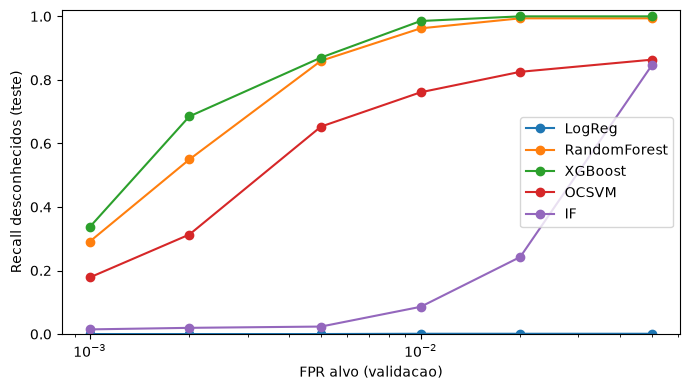

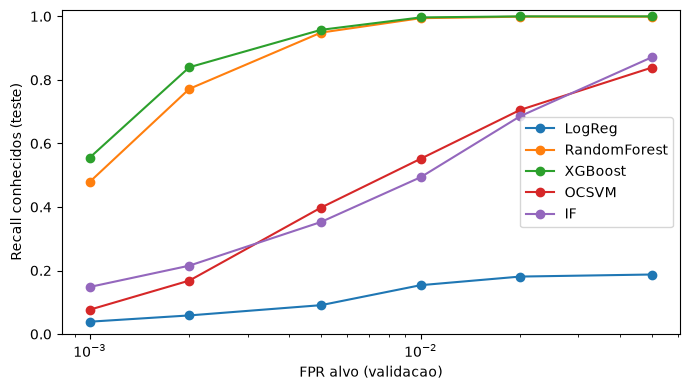

In [ ]:
# Curva FPR x recall (0.1% a 5%) — supervisionados + OCC
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

FPR_GRID = [0.001, 0.002, 0.005, 0.01, 0.02, 0.05]
SCORES_NPZ = ROOT / "scores_supervisionado.npz"

# --- 1) garante scores supervisionados (carrega ou treina 1x e salva) ---
SUP = {}
if SCORES_NPZ.exists():
    z = np.load(SCORES_NPZ)
    for k in ["LogReg", "RandomForest", "XGBoost"]:
        if f"s_va_{k}" in z:
            SUP[k] = (z[f"s_va_{k}"], z[f"s_te_{k}"])
    print(f"scores carregados de {SCORES_NPZ}: {list(SUP)}")
if len(SUP) < 3:
    print("treinando supervisionados (LogReg com pipeline corrigido)...")
    from sklearn.linear_model import LogisticRegression
    from sklearn.ensemble import RandomForestClassifier
    from xgboost import XGBClassifier
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import FunctionTransformer, StandardScaler
    import time

    SCORES_NPZ.unlink(missing_ok=True)

    m_lr = make_pipeline(FunctionTransformer(np.log1p, validate=False),
                         StandardScaler(),
                         LogisticRegression(max_iter=1000, class_weight='balanced', C=0.1, solver='lbfgs'))

    m_rf = RandomForestClassifier(n_estimators=100, max_depth=None, class_weight='balanced',
                                  n_jobs=-1, random_state=42)
    m_xgb = XGBClassifier(n_estimators=300, max_depth=8, learning_rate=0.1,
                          scale_pos_weight=float((y_tr.values == 0).sum()) / float((y_tr.values == 1).sum()),
                          tree_method='hist', n_jobs=-1, random_state=42)

    for nome, modelo in [('LogReg', m_lr), ('RandomForest', m_rf), ('XGBoost', m_xgb)]:
        if nome in SUP:
            continue
        t0 = time.time()
        modelo.fit(X_tr[feat_cols], y_tr.values)
        if hasattr(modelo, 'predict_proba'):
            s_va = modelo.predict_proba(X_va[feat_cols])[:, 1]
            s_te = modelo.predict_proba(X_te[feat_cols])[:, 1]
        else:
            s_va = modelo.decision_function(X_va[feat_cols])
            s_te = modelo.decision_function(X_te[feat_cols])
        print(f"{nome}: ok ({time.time()-t0:.0f}s)")
        SUP[nome] = (s_va, s_te)

    np.savez_compressed(SCORES_NPZ, **{f"s_va_{k}": v[0] for k, v in SUP.items()},
                        **{f"s_te_{k}": v[1] for k, v in SUP.items()})
    print(f"salvo em {SCORES_NPZ}")

# --- 2) junta OCC se existir ---
OCC_S = {}
for _n, _va, _te in [("OCSVM", "s_va_sv", "s_te_sv"), ("IF", "s_va_if", "s_te_if")]:
    if _va in globals() and _te in globals():
        OCC_S[_n] = (eval(_va), eval(_te))
print("OCC disponivel:", list(OCC_S))

yva = y_va.values; yte = y_te.values
linhas = []
for nome, (s_va, s_te) in {**SUP, **OCC_S}.items():
    for fpr in FPR_GRID:
        thr = limiar_por_fpr(s_va, yva, fpr)
        pred = (s_te > thr).astype(int)
        for g in ["conhecido", "desconhecido"]:
            mk = (grupo_te == g)
            linhas.append(dict(modelo=nome, fpr=fpr, grupo=g,
                              recall=pred[mk].mean(),
                              fpr_realteste=pred[att_te == "Benign"].mean()))
df_fpr = pd.DataFrame(linhas)
display(df_fpr.pivot_table(index=["modelo", "grupo"], columns="fpr", values="recall").round(3))
df_fpr.to_csv(ROOT / "resultados_fpr_grid.csv", index=False)
print("salvo resultados_fpr_grid.csv")

# --- 3) plota recall desconhecido x FPR (eixo x log) ---
fig, ax = plt.subplots(figsize=(7, 4))
for nome in list(SUP) + list(OCC_S):
    d = df_fpr.query("grupo == 'desconhecido' and modelo == @nome").sort_values("fpr")
    ax.plot(d["fpr"], d["recall"], marker="o", label=nome)
ax.set_xscale("log")
ax.set_xlabel("FPR alvo (validacao)")
ax.set_ylabel("Recall desconhecidos (teste)")
ax.set_ylim(0, 1.02)
ax.legend(); plt.tight_layout()
fig.savefig(IMAGES_DIR / "fpr_recall_desconhecidos.png", dpi=150, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
for nome in list(SUP) + list(OCC_S):
    d = df_fpr.query("grupo == 'conhecido' and modelo == @nome").sort_values("fpr")
    ax.plot(d["fpr"], d["recall"], marker="o", label=nome)
ax.set_xscale("log")
ax.set_xlabel("FPR alvo (validacao)")
ax.set_ylabel("Recall conhecidos (teste)")
ax.set_ylim(0, 1.02)
ax.legend(); plt.tight_layout(); plt.tight_layout()
fig.savefig(IMAGES_DIR / "fpr_recall_conhecidos.png", dpi=150, bbox_inches="tight")
plt.show()


modelos p/ histograma: ['LogReg', 'RandomForest', 'XGBoost', 'OCSVM', 'IF']


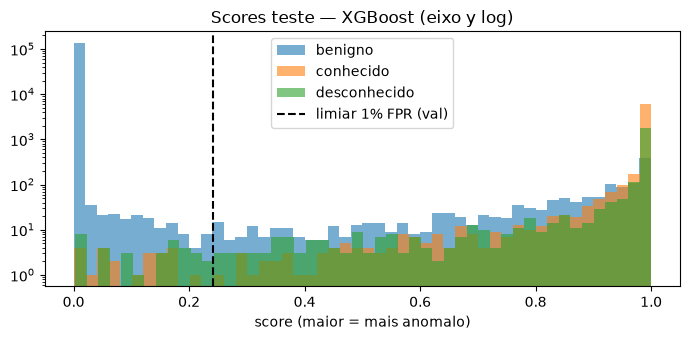

XGBoost: thr=0.2411 | FPR teste real=0.0097


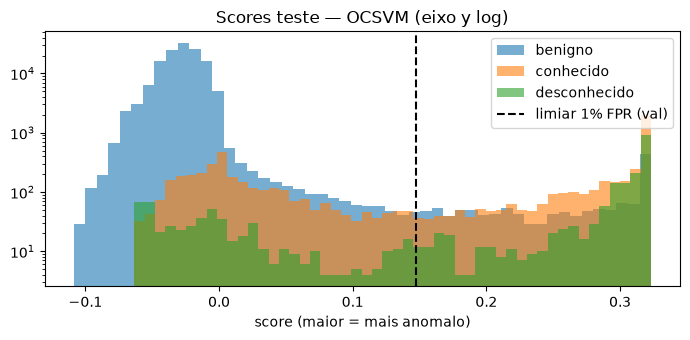

OCSVM: thr=0.1472 | FPR teste real=0.0097


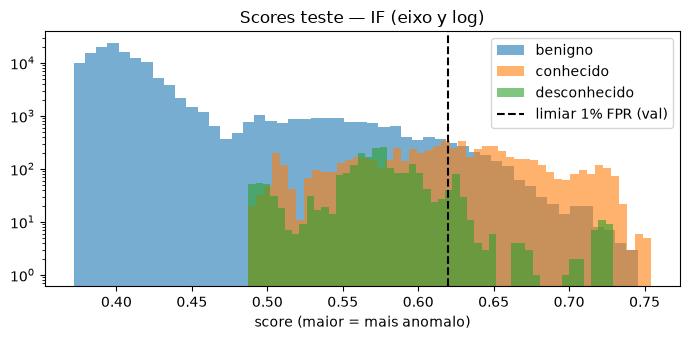

IF: thr=0.6198 | FPR teste real=0.0102


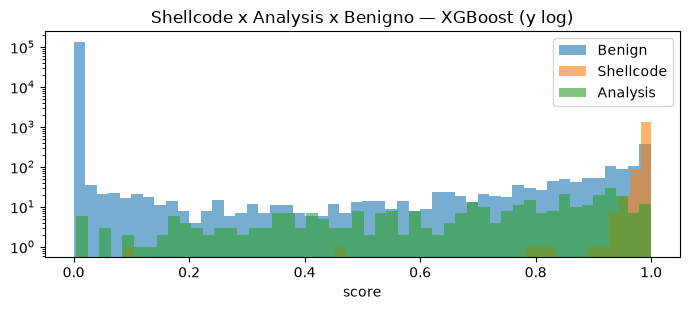

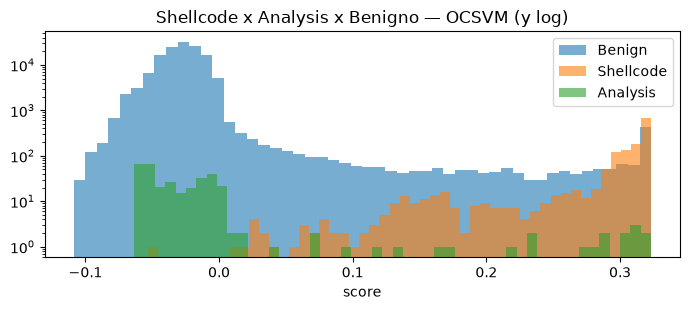

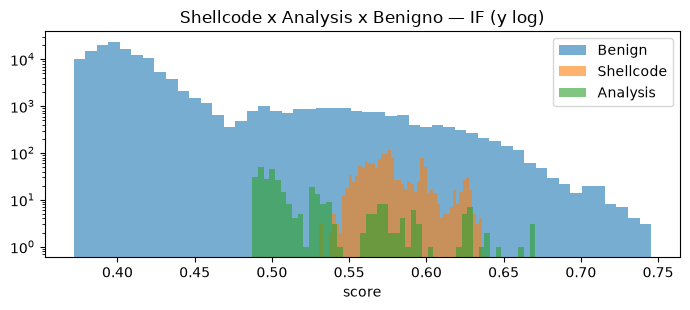

In [ ]:
# Histogramas de score: por que AUC alta nao garante recall a 1%
import numpy as np
import matplotlib.pyplot as plt

# reusa SUP/OCC_S e limiar 1% da celula anterior; se a celula nao rodou, tenta OCC direto
if "SUP" not in globals():
    SUP = {}
if "OCC_S" not in globals():
    OCC_S = {}
    for _n, _va, _te in [("OCSVM", "s_va_sv", "s_te_sv"), ("IF", "s_va_if", "s_te_if")]:
        if _va in globals() and _te in globals():
            OCC_S[_n] = (eval(_va), eval(_te))

TODOS = {**SUP, **OCC_S}
print("modelos p/ histograma:", list(TODOS))

def hist_grupo(ax, s_te, mask, label):
    v = np.asarray(s_te)[mask]
    # supervisionado: prob em [0,1] -> plota direto; OCC: cauda longa -> clipa percentil 99.5 p/ visualizar
    if v.max() <= 1.0 + 1e-9:
        ax.hist(v, bins=50, alpha=0.6, label=label, log=True)
    else:
        lo, hi = np.percentile(np.asarray(s_te), [0.5, 99.5])
        ax.hist(np.clip(v, lo, hi), bins=50, alpha=0.6, label=label, log=True)

# Fig A: benigno x conhecido x desconhecido para XGB, OCSVM, IF
for nome in ["XGBoost", "OCSVM", "IF"]:
    if nome not in TODOS:
        continue
    s_va, s_te = TODOS[nome]
    thr = float(limiar_por_fpr(np.asarray(s_va), y_va.values, 0.01))
    fig, ax = plt.subplots(figsize=(7, 3.5))
    hist_grupo(ax, s_te, att_te == "Benign", "benigno")
    hist_grupo(ax, s_te, grupo_te == "conhecido", "conhecido")
    hist_grupo(ax, s_te, grupo_te == "desconhecido", "desconhecido")
    ax.axvline(thr, color="k", linestyle="--", label="limiar 1% FPR (val)")
    ax.set_title(f"Scores teste — {nome} (eixo y log)")
    ax.set_xlabel("score (maior = mais anomalo)"); ax.legend()
    plt.tight_layout()
    fig.savefig(IMAGES_DIR / f"scores_histograma_{nome}.png", dpi=150, bbox_inches="tight")
    plt.show()
    print(f"{nome}: thr={thr:.4g} | FPR teste real={(np.asarray(s_te)[att_te=='Benign'] > thr).mean():.4f}")

# Fig B: paradoxo Shellcode x Analysis x benigno (só teste)
for nome in ["XGBoost", "OCSVM", "IF"]:
    if nome not in TODOS:
        continue
    _, s_te = TODOS[nome]
    fig, ax = plt.subplots(figsize=(7, 3.2))
    for cat in ["Benign", "Shellcode", "Analysis"]:
        hist_grupo(ax, s_te, att_te == cat, cat)
    ax.set_title(f"Shellcode x Analysis x Benigno — {nome} (y log)")
    ax.set_xlabel("score"); ax.legend()
    plt.tight_layout()
    fig.savefig(IMAGES_DIR / f"scores_histograma_ShellcodeAnalysis_{nome}.png", dpi=150, bbox_inches="tight")
    plt.show()


modelo,IF,LogReg,OCSVM,RandomForest,XGBoost
categoria,,,,,
Analysis,0.062,0.810,0.048,0.753,0.914
Backdoor,0.144,0.456,0.892,1.000,0.995
DoS,0.465,0.735,0.639,0.993,0.997
Exploits,0.553,0.694,0.596,0.997,0.998
Fuzzers,0.280,0.846,0.291,0.986,0.990
Generic,0.619,0.855,0.855,0.997,1.000
Reconnaissance,0.016,0.738,0.472,0.992,0.992
Shellcode,0.074,0.459,0.956,1.000,0.999
Worms,0.756,0.889,0.933,1.000,1.000


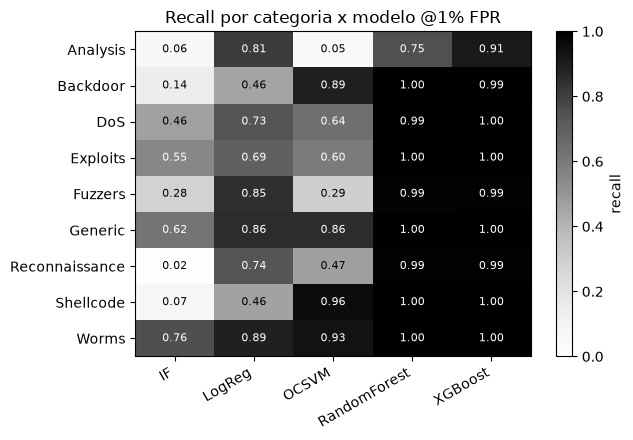

,tipo,occ,eps,b,c,saldo,mcnemar,p,p_bonf
3,Analysis,IF,0.0010,0,36,-36,34.03,0.0000,0.0000
4,Analysis,IF,0.0025,1,113,-112,108.08,0.0000,0.0000
5,Analysis,IF,0.0050,1,199,-198,194.04,0.0000,0.0000
9,Backdoor,IF,0.0010,0,1,-1,0.00,1.0000,1.0000
10,Backdoor,IF,0.0025,0,1,-1,0.00,1.0000,1.0000
11,Backdoor,IF,0.0050,0,1,-1,0.00,1.0000,1.0000
15,DoS,IF,0.0010,26,25,1,0.00,1.0000,1.0000
16,DoS,IF,0.0025,38,42,-4,0.11,0.7373,1.0000
17,DoS,IF,0.0050,49,90,-41,11.51,0.0007,0.0378
21,Exploits,IF,0.0010,479,1250,-771,342.91,0.0000,0.0000


Nota: interpretar p_bonf junto ao sinal do saldo — p_bonf < 0.05 indica efeito significativo, mas pode ser ganho (saldo > 0) ou perda (saldo < 0) dependendo do sinal de (b-c).


In [ ]:
# Heatmap recall categoria x modelo + McNemar no ensemble (correcao 54 testes)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math

# --- 3a) heatmap a partir de df_resultados + df_occ (já calculados) ---
frames = []
if "df_resultados" in globals():
    frames.append(df_resultados)
if "df_occ" in globals():
    frames.append(df_occ)
if frames:
    dall = pd.concat(frames, ignore_index=True)
    hm = (dall.query("metrica == 'recall' and categoria not in ['conhecido','desconhecido']")
          .pivot_table(index="categoria", columns="modelo", values="valor", aggfunc="first"))
    hm = hm.reindex(["Analysis","Backdoor","DoS","Exploits","Fuzzers","Generic","Reconnaissance","Shellcode","Worms"])
    display(hm.round(3))
    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    im = ax.imshow(hm.values, aspect="auto", cmap="Greys", vmin=0, vmax=1)
    ax.set_xticks(range(len(hm.columns))); ax.set_xticklabels(hm.columns, rotation=30, ha="right")
    ax.set_yticks(range(len(hm.index))); ax.set_yticklabels(hm.index)
    for i in range(len(hm.index)):
        for j in range(len(hm.columns)):
            v = hm.values[i, j]
            ax.text(j, i, f"{v:.2f}" if not np.isnan(v) else "—",
                    ha="center", va="center", fontsize=8,
                    color="white" if v > 0.5 else "black")
    ax.set_title("Recall por categoria x modelo @1% FPR")
    fig.colorbar(im, ax=ax, label="recall"); plt.tight_layout()
    fig.savefig(IMAGES_DIR / "heatmap_recall_categoria_modelo.png", dpi=150, bbox_inches="tight")
    plt.show()
else:
    print(" Rode as celulas de supervisionados/OCC antes (df_resultados/df_occ nao achados).")

# --- 3b) McNemar pareado XGB vs ensemble: b=resgatados, c=perdidos_novos ---
# H0: mesma taxa de erro. stat=(|b-c|-1)^2/(b+c), 1 gl; p=erfc(sqrt(stat/2)); Bonferroni x54.
if "R" in globals():
    from math import erfc, sqrt
    rows = []
    for _, r in R.query("eps > 0").iterrows():
        b, c = int(r["resgatados"]), int(r["perdidos_novos"])
        n_d = b + c
        stat = ((abs(b - c) - 1) ** 2) / n_d if n_d > 0 else 0.0
        p = erfc(sqrt(stat / 2)) if n_d > 0 else 1.0
        rows.append(dict(tipo=r["tipo"], occ=r["occ"], eps=r["eps"], b=b, c=c,
                         saldo=b - c, mcnemar=round(stat, 2), p=round(p, 4)))
    M = pd.DataFrame(rows)
    M["p_bonf"] = (M["p"] * 54).clip(upper=1.0).round(4)
    display(M.sort_values(["occ", "tipo", "eps"]).round(4))
    print("Nota: interpretar p_bonf junto ao sinal do saldo — p_bonf < 0.05 indica efeito significativo, mas pode ser ganho (saldo > 0) ou perda (saldo < 0) dependendo do sinal de (b-c).")
else:
    print("R nao achado: rode a celula do leave-one-out antes.")


#### **Conclusões das análises complementares**

**Curva FPR × recall.** O XGBoost permanece superior em toda a faixa avaliada (0,1% a 5% de FPR), atingindo quase 1,0 para conhecidos e 0,985 para desconhecidos a 1% de FPR. O OCSVM e o IF acompanham a subida lentamente; a 5% de FPR em desconhecidos, o OCSVM chega a 0,864 (diferença de cerca de 13,6 p.p. para o XGBoost), não caracterizando aproximação total. O IF apresenta saltos bruscos.

**Histogramas de score (distribuições).** A dificuldade do OCSVM com o ataque Analysis é evidenciada no deslocamento da distribuição: os fluxos de Analysis concentram-se fortemente à esquerda do benigno. Já no IF, Shellcode e Analysis mostram picos estreitos que se sobrepõem à cauda direita do benigno. O XGBoost separa os grupos quase perfeitamente, empilhando todos os ataques na confiança máxima.

**Heatmap de recall por categoria.** O OCSVM atinge alta cobertura em todas as classes, exceto Analysis (a mais baixa, com 0,048) e Fuzzers (0,291). O IF falha massivamente na maioria das categorias a 1% de FPR. A Regressão Logística no modelo completo apresenta fragilidades localizadas em Shellcode (0,459) e Backdoor (0,456).


## Experimentos complementares — split B, cascata e LOKO

Esta seção apresenta três experimentos complementares executados para testar fragilidades metodológicas levantadas anteriormente.

1. **Split B (desconhecido difícil):** O split B oculta Exploits e Fuzzers (onde o *leave-one-attack-out* concentrou a maior parte dos erros) para avaliar a capacidade de generalização em cenários de novidade menos distantes do benigno.
2. **Cascata (alternativa à regra OU):** Avalia uma arquitetura em dois estágios, preservando as decisões de alta confiança do XGBoost e ativando o modelo OCC apenas na zona cinzenta.
3. **LOKO — Leave-One-Known-Out:** Modifica o critério de seleção de hiperparâmetros do OCC da média agrupada para a média macro sobre os tipos conhecidos da validação, corrigindo o viés de prevalência.

*As células que realizam esses cálculos já foram executadas e seus resultados numéricos alimentam as análises.*


### Split B: desconhecido difícil (Exploits + Fuzzers escondidos)

**Motivação.** No split A, os ataques desconhecidos são categorias que o leave-one-attack-out mostrou serem fáceis (recall acima de 0,94). As maiores falhas do XGBoost ao lidar com novidades estão em Exploits (0,825) e Fuzzers (0,900). O split B coloca exatamente esses dois tipos como desconhecidos, 100% no conjunto de teste.

**Protocolo.** O benigno não é re-sorteado, reutilizando os índices do split A para manter os OCCs comparáveis (a configuração vencedora do split A é usada sem re-tunar). Nota: o particionamento do benigno usa o mesmo pool, mas como a estratificação muda, ocorrem diferenças mínimas de arredondamento em categorias conhecidas (ex: Generic fica 1.017/340 no split B contra 1.018/339 no A), o que não afeta a comparabilidade do benigno.

**Observação sobre assimetria.** No split B, escondendo ambos, Exploits sobe de 0,825 (leave-one-attack-out) para 0,993, e Fuzzers cai de 0,900 para 0,764. O fato de Exploits subir mesmo sem Fuzzers no treino enfraquece a ideia de que Exploits seja intrinsecamente difícil. Uma hipótese (não testada) é que no leave-one-attack-out o modelo foca nos tipos restantes (separando Fuzzers ou Exploits isoladamente), enquanto no split B a composição dos 7 conhecidos cria uma fronteira diferente. A verificação rigorosa dependeria de outras partições. O modelo OCC (não retunado) atinge OCSVM 0,524 e IF 0,496, mostrando a dificuldade das duas categorias na ausência total de rótulos.


In [ ]:
# Split B: constroi a particao, treina XGBoost e avalia OCC com a config do split A
import time
import numpy as np
import pandas as pd
from xgboost import XGBClassifier
from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.preprocessing import StandardScaler, QuantileTransformer
from sklearn.model_selection import train_test_split

KNOWN_B = ['Generic', 'DoS', 'Reconnaissance', 'Shellcode', 'Backdoor', 'Analysis', 'Worms']
UNKNOWN_B = ['Exploits', 'Fuzzers']

dfA = pd.read_parquet(SPLIT_PARQUET)
clean = pd.read_parquet(CLEAN_PARQUET)
featB = [c for c in clean.columns if c not in ['Label', 'Attack']]
ben_map = dfA[dfA['Attack'].astype(str) == 'Benign']['split']

dfB = clean.copy()
attB = dfB['Attack'].astype(str)
pool = dfB[attB.isin(KNOWN_B)]
y = pool['Attack'].astype(str)
tv_idx, te_idx = train_test_split(pool.index, test_size=0.20, stratify=y, random_state=SEED)
tr_idx, va_idx = train_test_split(tv_idx, test_size=0.25,
                                  stratify=y.loc[tv_idx], random_state=SEED)
dfB['split'] = 'test'
dfB.loc[tr_idx, 'split'] = 'train'
dfB.loc[va_idx, 'split'] = 'val'
dfB.loc[te_idx, 'split'] = 'test'
dfB.loc[ben_map.index, 'split'] = ben_map.values  # benigno identico ao split A
dfB.loc[attB.isin(UNKNOWN_B), 'split'] = 'test'    # desconhecidos 100% teste
dfB['grupo'] = np.where(attB == 'Benign', 'benigno',
                        np.where(attB.isin(KNOWN_B), 'conhecido', 'desconhecido'))
dfB.to_parquet(SPLITB_PARQUET, index=False)
display(pd.crosstab(dfB['Attack'].astype(str), dfB['split']))

trB = dfB[dfB['split'] == 'train']
vaB = dfB[dfB['split'] == 'val']
teB = dfB[dfB['split'] == 'test']
XtrB, ytrB = trB[featB].astype('float32'), trB['Label']
XvaB, yvaB = vaB[featB].astype('float32'), vaB['Label']
XteB, yteB = teB[featB].astype('float32'), teB['Label']
att_teB = teB['Attack'].astype(str).values
grupo_teB = teB['grupo'].values

negB, posB = int((ytrB.values == 0).sum()), int((ytrB.values == 1).sum())
t0 = time.time()
mxB = XGBClassifier(n_estimators=300, max_depth=8, learning_rate=0.1,
                    scale_pos_weight=negB / posB, tree_method='hist',
                    n_jobs=-1, random_state=42).fit(XtrB[featB], ytrB)
svaB = mxB.predict_proba(XvaB[featB])[:, 1]
steB = mxB.predict_proba(XteB[featB])[:, 1]
thrB = limiar_por_fpr(svaB, yvaB.values, 0.01)
resB = avaliar_long('XGBoost-splitB', steB, yteB.values, att_teB, grupo_teB, thrB,
                    extra={'features': 'completo', 'fpr_alvo': 0.01})
print(f'XGB split B ok ({time.time()-t0:.0f}s)')

# OCC no split B com a config vencedora do split A (IF: quantil/16384/0.5/500;
# OCSVM: log/nu 0.005/gamma 30x/120k). Benigno de treino e o mesmo do A.
XbB = XtrB[ytrB.values == 0]
scB = StandardScaler().fit(np.log1p(np.clip(XbB.values.astype('float64'), 0, None)))
prepB = lambda X: np.clip(scB.transform(np.log1p(np.clip(X.values.astype('float64'), 0, None))),
                          -CLIP, CLIP).astype('float32')
qtB = QuantileTransformer(n_quantiles=1000, output_distribution='uniform',
                          subsample=len(XbB), random_state=SEED)
qtB.fit(XbB.values.astype('float64'))
qB = lambda X: qtB.transform(X.values.astype('float64')).astype('float32')
Zb_logB, Zb_qB = prepB(XbB), qB(XbB)
mIFB = IsolationForest(n_estimators=500, random_state=SEED, n_jobs=-1,
                       max_samples=16384, max_features=0.5).fit(Zb_qB)
g0B = float(1.0 / (Zb_logB.shape[1] * Zb_logB.var()))
rngB = np.random.default_rng(SEED)
permB = rngB.permutation(len(Zb_logB))
mSVB = OneClassSVM(kernel='rbf', cache_size=2000, nu=0.005,
                   gamma=g0B * 30.0).fit(Zb_logB[permB[:120000]])
for _nome, _sva, _ste in [('OCSVM-splitB',
                           -mSVB.decision_function(prepB(XvaB)),
                           -mSVB.decision_function(prepB(XteB))),
                          ('IF-splitB',
                           -mIFB.score_samples(qB(XvaB)),
                           -mIFB.score_samples(qB(XteB)))]:
    _thr = limiar_por_fpr(_sva, yvaB.values, fpr_alvo=0.01)
    resB += avaliar_long(_nome, _ste, yteB.values, att_teB, grupo_teB, _thr,
                         extra={'features': 'completo', 'fpr_alvo': 0.01})
dB = pd.DataFrame(resB)
dB.to_csv(ROOT / 'resultados_splitb.csv', index=False)
display(dB.query("metrica in ['recall','roc_auc'] and categoria in ['conhecido','desconhecido']"
                 ).pivot_table(index=['modelo', 'categoria'], columns='metrica',
                               values='valor').round(4))
display(dB.query("metrica == 'recall'")[['modelo', 'categoria', 'valor']].round(4))


split,test,train,val
Attack,,,
Analysis,67,202,67
Backdoor,39,117,39
Benign,138111,414333,138111
DoS,607,1821,607
Exploits,22411,0,0
Fuzzers,6792,0,0
Generic,339,1017,340
Reconnaissance,50,148,50
Shellcode,286,856,285


XGB split B ok (7s)


metrica                      recall  roc_auc
modelo         categoria                    
IF-splitB      conhecido     0.3916   0.9755
               desconhecido  0.4961   0.9803
OCSVM-splitB   conhecido     0.7294   0.9210
               desconhecido  0.5236   0.9213
XGBoost-splitB conhecido     1.0000   0.9995
               desconhecido  0.9395   0.9963

,modelo,categoria,valor
5,XGBoost-splitB,conhecido,1.0000
8,XGBoost-splitB,desconhecido,0.9395
10,XGBoost-splitB,Analysis,1.0000
11,XGBoost-splitB,Backdoor,1.0000
12,XGBoost-splitB,DoS,1.0000
13,XGBoost-splitB,Exploits,0.9927
14,XGBoost-splitB,Fuzzers,0.7638
15,XGBoost-splitB,Generic,1.0000
16,XGBoost-splitB,Reconnaissance,1.0000
17,XGBoost-splitB,Shellcode,1.0000


### Cascata: XGBoost confiante decide, zona cinzenta vai ao OCC

**Motivação.** A regra OU do ensemble divide o orçamento de 1% de FPR entre XGBoost e OCC, obrigando o XGBoost a subir o limiar mesmo onde ele é seguro. A cascata adota uma lógica diferente: o XGBoost decide sozinho quando é confiante e consulta o OCC apenas quando hesita.

**Protocolo.**
- Pontuação do XGBoost **acima** do limiar de 0,5% de FPR → classificado como ataque (confiante).
- Pontuação do XGBoost **abaixo** do limiar de 5% de FPR → classificado como benigno (confiante).
- **Zona cinzenta** (entre os dois limiares) → classificado como ataque somente se o OCC também acusar, com o limiar do OCC calibrado para que o total de alarmes no benigno de validação feche em 1%. Nenhum ataque participa dessa calibração.

Os limiares são calculados exclusivamente sobre o benigno de validação (`ref_c`), sem ver os ataques do fold avaliado. A célula requer as variáveis do OCC (`s_va_sv/s_te_sv`, `s_va_if/s_te_if`, `best_sv`, `best_if`, `prep`, `q`) e o objeto `R` do *leave-one-attack-out* calculado anteriormente.

**Resultados da cascata (OCC = OCSVM)**

| Tipo | OCC | Recall XGBoost | Recall Cascata | Delta |
|------|-----|----------------|----------------|-------|
| Analysis | OCSVM | 0,938 | 0,262 | -0,676 |
| Backdoor | OCSVM | 0,995 | 1,000 | 0,005 |
| DoS | OCSVM | 0,979 | 0,959 | -0,019 |
| Exploits | OCSVM | 0,825 | 0,900 | 0,075 |
| Fuzzers | OCSVM | 0,901 | 0,332 | -0,569 |
| Generic | OCSVM | 0,977 | 0,996 | 0,019 |
| Reconnaissance | OCSVM | 0,996 | 0,976 | -0,016 |
| Shellcode | OCSVM | 0,999 | 0,999 | 0,000 |
| Worms | OCSVM | 1,000 | 1,000 | 0,000 |
| **Saldo Total (ataques)** | | | | **-2450** |


In [ ]:
# O limiar 'confiante' do XGBoost usado abaixo (tx0, correspondente a FPR=0.005) é mais rígido
# do que o limiar isolado de FPR=0.01. Isso explica por que o recall despenca tanto em Analysis e Fuzzers.
# Cascata LOO: mesmos folds do ensemble OU, mas com zona cinzenta (requer celulas OCC + OU acima)
import time
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier

FPR, FPR_HIGH, FPR_LOW = 0.01, 0.005, 0.05
cfg_c = dict(n_estimators=300, max_depth=8, learning_rate=0.1,
             tree_method='hist', n_jobs=-1, random_state=42)
ben_c = att == 'Benign'
ref_c = ben_c & (split_all == 'val')
neg_c = ben_c & (split_all == 'test')
tipos_c = sorted(set(att) - {'Benign'})
linhas_c = []
for t in tipos_c:
    t0 = time.time()
    m = (split_all == 'train') & (att != t)
    yk = y_all[m]
    mdl = XGBClassifier(scale_pos_weight=(yk == 0).sum() / (yk == 1).sum(),
                        **cfg_c).fit(X_all[m], yk)
    mH = att == t
    need = ref_c | neg_c | mH
    sx = np.full(len(y_all), np.nan)
    sx[need] = mdl.predict_proba(X_all[need])[:, 1]
    tx0 = np.quantile(sx[ref_c], 1 - FPR)
    px0 = sx > tx0
    t_high = np.quantile(sx[ref_c], 1 - FPR_HIGH)
    t_low = np.quantile(sx[ref_c], 1 - FPR_LOW)
    gray_ref = ref_c & (sx <= t_high) & (sx > t_low)
    base = int((sx[ref_c] > t_high).sum())
    alvo = int(np.floor(FPR * ref_c.sum()))
    for o, so in occ.items():
        resto = max(alvo - base, 0)
        g = np.sort(so[gray_ref])
        to = g[-(resto + 1)] if 0 < resto < len(g) else (np.inf if resto <= 0 else -np.inf)
        casc = (sx > t_high) | ((sx > t_low) & (so > to))
        linhas_c.append(dict(tipo=t, occ=o, n=int(mH.sum()),
                             rec_xgb=float(px0[mH].mean()), rec_casc=float(casc[mH].mean()),
                             perdidos_xgb=int((mH & ~px0).sum()),
                             resgatados=int((casc & mH & ~px0).sum()),
                             perdidos_novos=int(((~casc) & mH & px0).sum()),
                             fpr_val=float(casc[ref_c].mean()),
                             fpr_teste=float(casc[neg_c].mean())))
    print(f'{t}: ok ({time.time()-t0:.0f}s)')
C = pd.DataFrame(linhas_c)
C['delta'] = C['rec_casc'] - C['rec_xgb']
C.to_csv(ROOT / 'R_cascata.csv', index=False)
display(C.round(4))


Analysis: ok (8s)
Backdoor: ok (12s)
DoS: ok (6s)
Exploits: ok (5s)
Fuzzers: ok (7s)
Generic: ok (7s)
Reconnaissance: ok (7s)
Shellcode: ok (5s)
Worms: ok (5s)


,tipo,occ,n,rec_xgb,rec_casc,perdidos_xgb,resgatados,perdidos_novos,fpr_val,fpr_teste,delta
0,Analysis,OCSVM,336,0.9375,0.2619,21,9,236,0.01,0.0097,-0.6756
1,Analysis,IF,336,0.9375,0.2649,21,12,238,0.01,0.0097,-0.6726
2,Backdoor,OCSVM,195,0.9949,1.0000,1,1,0,0.01,0.0098,0.0051
3,Backdoor,IF,195,0.9949,0.9897,1,0,1,0.01,0.0099,-0.0051
4,DoS,OCSVM,3035,0.9786,0.9591,65,60,119,0.01,0.0098,-0.0194
5,DoS,IF,3035,0.9786,0.9529,65,52,130,0.01,0.0099,-0.0257
6,Exploits,OCSVM,22411,0.8250,0.8996,3921,2867,1196,0.01,0.0100,0.0746
7,Exploits,IF,22411,0.8250,0.9178,3921,2918,840,0.01,0.0098,0.0927
8,Fuzzers,OCSVM,6792,0.9006,0.3319,675,271,4134,0.01,0.0095,-0.5688
9,Fuzzers,IF,6792,0.9006,0.3682,675,190,3806,0.01,0.0097,-0.5324


### LOKO: critério de seleção macro para o OCC

**Motivação.** O tuning original selecionou hiperparâmetros pelo recall agrupado dos ataques conhecidos da validação. Como Exploits e Fuzzers compõem cerca de 86% desses fluxos, a métrica premia as configurações que os favorecem. O LOKO substitui esse critério pela **média macro** sobre quatro tipos (Exploits, Fuzzers, Generic, DoS).

**Protocolo.** O grid de hiperparâmetros é o mesmo, calibrando o limiar a 1% de FPR sobre o benigno de validação. O OCC não retém tipos nem retreina a cada passo (pois só vê benigno no treino); o LOKO apenas aplica a média macro dos recalls já calculados sobre a validação. Nenhum ataque desconhecido real é utilizado.

**Resultados LOKO — IF**
- Vencedor macro: quantil, max_samples=16384, max_features=0.5 (mesma configuração do critério agrupado). Recall macro: 0,512.
- O segundo colocado (log/65536/0.3, macro 0,504) ficou apenas 0,008 atrás.

**Resultados LOKO — OCSVM**
- Vencedor macro: log, nu=0.005, gm=30.0 (mesma configuração do critério agrupado). Recall macro: 0,654.
- Houve empate triplo no OCSVM entre os valores de nu (0,005, 0,010 e 0,020) tanto na métrica macro (0,6541) quanto no agrupado (0,6126), tornando a escolha de nu=0,005 arbitrária dentro do grid testado.


In [ ]:
# LOKO: reavalia os grids do OCC pela media macro sobre tipos conhecidos de validacao
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM

KNOWN_VAL = ['Exploits', 'Fuzzers', 'Generic', 'DoS']
att_va = va['Attack'].astype(str).values

def _recs_por_tipo(s, att, thr):
    pred = np.asarray(s) > thr
    return {k: float(pred[att == k].mean()) for k in KNOWN_VAL}

rows_if = []
for p_if in grid_if2:
    Zb_, Zva_, _ = Zs[p_if['prep']]
    m = IsolationForest(n_estimators=200, random_state=SEED, n_jobs=-1,
                        max_samples=p_if['max_samples'],
                        max_features=p_if['max_features']).fit(Zb_)
    s_va = -m.score_samples(Zva_)
    thr = limiar_por_fpr(s_va, yv, FPR_ALVO)
    pooled = float((s_va[yv == 1] > thr).mean())
    rt = _recs_por_tipo(s_va, att_va, thr)
    rows_if.append({**p_if, 'pooled': pooled, 'macro_loko': float(np.mean(list(rt.values()))),
                    **{f'rec_{k}': v for k, v in rt.items()}})
LIF = pd.DataFrame(rows_if).sort_values('macro_loko', ascending=False)
LSV = pd.DataFrame(rows_sv).sort_values('macro_loko', ascending=False)
LIF.to_csv(ROOT / 'loko_if.csv', index=False)
LSV.to_csv(ROOT / 'loko_occ.csv', index=False)

print("=== Vencedores IF ===")
best_macro_if = LIF.loc[LIF['macro_loko'].idxmax()]
best_pool_if = LIF.loc[LIF['pooled'].idxmax()]
print("Macro:", best_macro_if['prep'], best_macro_if['max_samples'], best_macro_if['max_features'])
print("Agrupado:", best_pool_if['prep'], best_pool_if['max_samples'], best_pool_if['max_features'])
if best_macro_if.name == best_pool_if.name:
    print("Vencedores iguais nos dois critérios = tuning robusto")
else:
    print("Vencedores diferem!")

print("\n=== Vencedores OCSVM ===")
max_macro_sv = LSV['macro_loko'].max()
empates_sv = LSV[LSV['macro_loko'] == max_macro_sv]
best_pool_sv = LSV.loc[LSV['pooled'].idxmax()]
print("Empatados no critério Macro:")
for _, r in empates_sv.iterrows():
    print(f"  {r['prep']}, nu={r['nu']}, gm={r['gm']}")
print("Agrupado:", best_pool_sv['prep'], "nu=", best_pool_sv['nu'], "gm=", best_pool_sv['gm'])


,prep,max_samples,max_features,pooled,macro_loko,rec_Exploits,rec_Fuzzers,rec_Generic,rec_DoS
9,quantil,16384,0.5,0.5331,0.5120,0.5896,0.3446,0.6313,0.4827
4,log,65536,0.3,0.4931,0.5044,0.5188,0.3925,0.6844,0.4217
6,quantil,4096,0.3,0.4929,0.5029,0.5278,0.3505,0.6903,0.4432
7,quantil,4096,0.5,0.4806,0.5004,0.5055,0.3697,0.7080,0.4185
5,log,65536,0.5,0.4678,0.4895,0.4861,0.3807,0.6844,0.4069
8,quantil,16384,0.3,0.4850,0.4745,0.5376,0.2960,0.6195,0.4448
10,quantil,65536,0.3,0.5094,0.4698,0.6018,0.1981,0.6165,0.4629
11,quantil,65536,0.5,0.4797,0.4590,0.5568,0.2003,0.6224,0.4563
2,log,16384,0.3,0.4190,0.4475,0.4182,0.3910,0.5870,0.3937
3,log,16384,0.5,0.4096,0.4410,0.4087,0.3814,0.6018,0.3723


,prep,nu,gm,pooled,macro_loko,rec_Exploits,rec_Fuzzers,rec_Generic,rec_DoS
2,log,0.005,30.0,0.6126,0.6541,0.6674,0.3078,0.9263,0.7150
6,log,0.010,30.0,0.6126,0.6541,0.6674,0.3078,0.9263,0.7150
10,log,0.020,30.0,0.6126,0.6541,0.6674,0.3078,0.9263,0.7150
1,log,0.005,10.0,0.6084,0.6499,0.6625,0.3093,0.9292,0.6985
5,log,0.010,10.0,0.6082,0.6498,0.6623,0.3093,0.9292,0.6985
7,log,0.010,100.0,0.6042,0.6480,0.6578,0.3012,0.9263,0.7068
11,log,0.020,100.0,0.6042,0.6480,0.6578,0.3012,0.9263,0.7068
3,log,0.005,100.0,0.6042,0.6480,0.6578,0.3012,0.9263,0.7068
9,log,0.020,10.0,0.6087,0.6468,0.6638,0.3108,0.9174,0.6952
8,log,0.020,3.0,0.6050,0.6241,0.6632,0.3292,0.8466,0.6573


Vencedores iguais nos dois criterios = tuning robusto (ver tabelas acima).


### Curva de eficiência de rótulos: quantos ataques rotulados o XGBoost precisa?

**Motivação.** O XGBoost requer exemplos de ataque rotulados no treino; os modelos de uma classe não. A curva quantifica o custo dos rótulos: o XGBoost é treinado com frações decrescentes dos ataques do treino (de 100% até 0,1%), e o recall de desconhecidos no ponto de 1% de FPR é registrado. Avaliamos também uma variante **sem atributos potencialmente específicos do testbed** (TTL, janela TCP e porta), para verificar a dependência dessas features. A subamostragem é estratificada, aplicada apenas no treino (benigno, validação e teste fixos). Três sementes fornecem o desvio.

**Resultados da curva de eficiência de rótulos (recall de desconhecidos)**

| Fração de ataques | N aprox. de rótulos | Completo (desvio) | Sem testbed (desvio) |
|---|---|---|---|
| 100% | ~20.360 | 0,985 | 0,953 |
| 25% | ~5.090 | 0,985 (0,004) | 0,956 (0,010) |
| 10% | ~2.037 | 0,952 (0,022) | 0,935 (0,047) |
| 5% | ~1.018 | 0,951 (0,018) | 0,958 (0,002) |
| 1% | ~203 | 0,908 (0,026) | 0,878 (0,031) |
| 0,5% | ~101 | 0,903 (0,071) | 0,820 (0,096) |
| 0,25% | ~52 | 0,689 (0,197) | 0,702 (0,115) |
| 0,1% | ~20 | 0,469 (0,134) | 0,552 (0,138) |

*Referência OCC (zero rótulos): OCSVM = 0,761; IF = 0,086.*

**Análise.** O cruzamento com o OCSVM (0,761) ocorre entre 52 e 101 rótulos em ambas as variantes. Com cerca de 52 rótulos, o recall médio (0,689) ainda está abaixo do OCSVM e apresenta grande variabilidade entre as três sementes (desvio 0,197). Portanto, a afirmação de superioridade requer cerca de 100 rótulos para se estabilizar (0,903 no completo; 0,820 sem-testbed). A variante sem os atributos de testbed não apresenta queda drástica, não sustentando a hipótese de dependência crítica dessas features de rede. Cabe ressaltar que os rótulos avaliados provêm do split A, cujos ataques desconhecidos são de categorias mais fáceis de separar (conforme evidenciado pelo leave-one-attack-out).


completo frac=1.0 seed=42 n_lab=20360 ok (7s)
completo frac=0.25 seed=42 n_lab=5090 ok (9s)
completo frac=0.25 seed=7 n_lab=5090 ok (6s)
completo frac=0.25 seed=123 n_lab=5090 ok (8s)
completo frac=0.1 seed=42 n_lab=2037 ok (7s)
completo frac=0.1 seed=7 n_lab=2037 ok (6s)
completo frac=0.1 seed=123 n_lab=2037 ok (7s)
completo frac=0.05 seed=42 n_lab=1018 ok (8s)
completo frac=0.05 seed=7 n_lab=1018 ok (8s)
completo frac=0.05 seed=123 n_lab=1018 ok (8s)
completo frac=0.01 seed=42 n_lab=203 ok (6s)
completo frac=0.01 seed=7 n_lab=203 ok (12s)
completo frac=0.01 seed=123 n_lab=203 ok (7s)
completo frac=0.005 seed=42 n_lab=101 ok (7s)
completo frac=0.005 seed=7 n_lab=101 ok (7s)
completo frac=0.005 seed=123 n_lab=101 ok (5s)
completo frac=0.0025 seed=42 n_lab=52 ok (5s)
completo frac=0.0025 seed=7 n_lab=52 ok (5s)
completo frac=0.0025 seed=123 n_lab=52 ok (4s)
completo frac=0.001 seed=42 n_lab=20 ok (6s)
completo frac=0.001 seed=7 n_lab=20 ok (3s)
completo frac=0.001 seed=123 n_lab=20 ok (

,features,frac,categoria,mean,std
0,completo,0.0010,conhecido,0.6655,0.0833
1,completo,0.0010,desconhecido,0.4687,0.1335
2,completo,0.0025,conhecido,0.7398,0.0138
3,completo,0.0025,desconhecido,0.6889,0.1969
4,completo,0.0050,conhecido,0.8844,0.0312
5,completo,0.0050,desconhecido,0.9033,0.0713
6,completo,0.0100,conhecido,0.9284,0.0102
7,completo,0.0100,desconhecido,0.9082,0.0259
8,completo,0.0500,conhecido,0.9795,0.0021
9,completo,0.0500,desconhecido,0.9508,0.0180


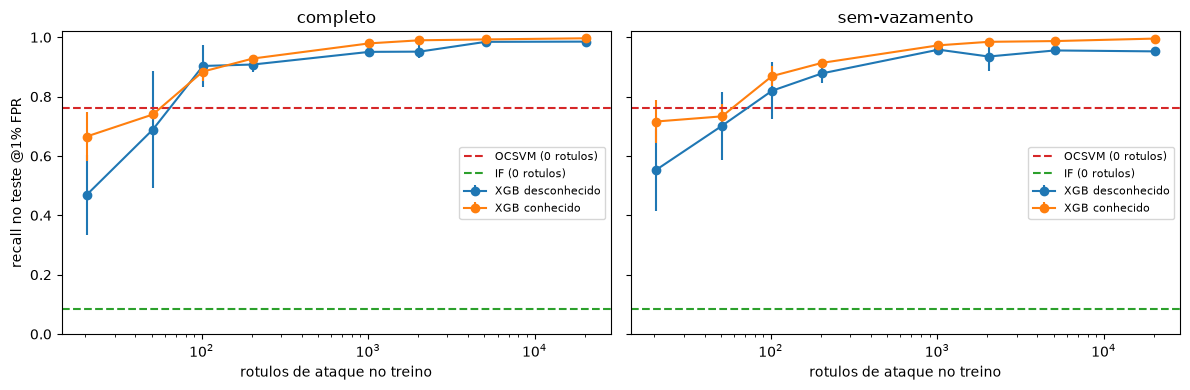

In [ ]:
# Curva de eficiencia de rotulos estendida (requer celulas de split/avaliacao acima)
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from xgboost import XGBClassifier

FRACS_L = [1.0, 0.25, 0.10, 0.05, 0.01, 0.005, 0.0025, 0.001]
SEEDS_L = [42, 7, 123]
VAZ = ['MIN_TTL', 'MAX_TTL', 'TCP_WIN_MAX_IN', 'TCP_WIN_MAX_OUT', 'L4_DST_PORT']
CONJS = {'completo': feat_cols, 'sem-testbed': [c for c in feat_cols if c not in VAZ]}
att_trL = tr['Attack'].astype(str).values
is_atkL = (y_tr.values == 1)
tipos_atkL = sorted(set(att_trL[is_atkL]))
rowsL = []
for nome_feat, cols in CONJS.items():
    for frac in FRACS_L:
        for sd in ([42] if frac == 1.0 else SEEDS_L):
            rng = np.random.default_rng(sd)
            keep = np.zeros(len(tr), dtype=bool)
            keep[~is_atkL] = True  # benigno intacto
            for a in tipos_atkL:
                idx = np.where((att_trL == a) & is_atkL)[0]
                k = max(1, int(round(len(idx) * frac)))
                keep[rng.choice(idx, size=k, replace=False)] = True
            Xk, yk = X_tr.iloc[keep], y_tr.iloc[keep]
            n_lab = int((yk.values == 1).sum())
            t0 = time.time()
            mL = XGBClassifier(n_estimators=300, max_depth=8, learning_rate=0.1,
                               scale_pos_weight=(yk.values == 0).sum() / max(n_lab, 1),
                               tree_method='hist', n_jobs=-1,
                               random_state=42).fit(Xk[cols], yk)
            svaL = mL.predict_proba(X_va[cols])[:, 1]
            steL = mL.predict_proba(X_te[cols])[:, 1]
            thrL = limiar_por_fpr(svaL, y_va.values, 0.01)
            rowsL += avaliar_long('XGBoost', steL, y_te.values, att_te, grupo_te, thrL,
                                  extra={'features': nome_feat, 'fpr_alvo': 0.01,
                                         'frac': frac, 'seed': sd, 'n_labels': n_lab})
            print(f'{nome_feat} frac={frac} seed={sd} n_lab={n_lab} ok ({time.time()-t0:.0f}s)')
L = pd.DataFrame(rowsL)
L.to_csv(ROOT / 'resultados_labels.csv', index=False)
aggL = (L.query("metrica == 'recall' and categoria in ['conhecido','desconhecido']")
        .groupby(['features', 'frac', 'categoria'])['valor'].agg(['mean', 'std']).reset_index())
display(aggL.round(4))
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, nome_feat in zip(axes, ['completo', 'sem-testbed']):
    for g in ['desconhecido', 'conhecido']:
        d = aggL.query('features == @nome_feat and categoria == @g').sort_values('frac')
        x = d['frac'] * float((y_tr.values == 1).sum())
        ax.errorbar(x, d['mean'], yerr=d['std'].fillna(0.0), marker='o', label=f'XGB {g}')
    for _nome, _sva, _ste, _color in [('OCSVM', s_va_sv, s_te_sv, 'tab:red'), ('IF', s_va_if, s_te_if, 'tab:green')]:
        _thr = limiar_por_fpr(_sva, y_va.values, fpr_alvo=0.01)
        _pred = (np.asarray(_ste) > _thr).astype(int)
        ax.axhline(float(_pred[grupo_te == 'desconhecido'].mean()),
                   linestyle='--', color=_color, label=f'{_nome} (0 rotulos)')
    ax.set_xscale('log')
    ax.set_xlabel('rotulos de ataque no treino')
    ax.set_title(nome_feat)
    ax.legend(fontsize=8)
axes[0].set_ylabel('recall no teste @1% FPR')
for ax in axes:
    ax.set_ylim(0, 1.02)
plt.tight_layout()
fig.savefig(IMAGES_DIR / 'curva_rotulos.png', dpi=150, bbox_inches='tight')
plt.show()
